# **Análisis univariado**

La unidad de análisis es el paciente de la cohorte maestra HXGEN (`base_full`). Se conservan los 391 registros, incluidos los que no tienen AOO. Esta sección describe cada variable por separado; no prueba asociaciones con AOO ni selecciona predictores. Los porcentajes válidos excluyen faltantes; los porcentajes totales usan toda la cohorte. Las mediciones contemporáneas o posteriores al inicio describen el estado clínico, sin atribuirles temporalidad previa.

**Nota metodológica sobre secciones previas.** En las listas `GRUPOS_DEMO` y `GRUPOS_NEURO` algunos textos no coinciden exactamente con los encabezados del Excel; esto puede dejar variables fuera de los subgrupos. Además, `base_aoo` se creó antes de algunas columnas de auditoría y transformaciones de `base_full`, y las conversiones numéricas de la sección 20 pueden generar faltantes nuevos. Importa porque una selección automática por nombre, por dtype o por `base_aoo` podría omitir variables o usar versiones distintas. La celda 59 de tabaquismo también buscaba un nombre que no existe y podía causar `KeyError`; en esta copia se añadió una guarda explícita y una advertencia, sin recodificar valores desconocidos. Aquí se propone resolver nombres con el diccionario de columnas realmente integradas, verificar las conversiones y usar `base_full` como única fuente para descripciones. No se altera la lógica anterior.


## **1. Configuración inicial y carga de datos**

In [22]:
import math
import pickle
import re
import textwrap
import unicodedata
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from IPython.display import display, Markdown


from funciones.funciones import *
from funciones.funciones_normalizacion import *

SALIDAS = Path("salidas")
DATA_DIR = Path("datos")
PATH_NEURO = DATA_DIR / "neuropsicologia-casos.xlsx"
PATH_MOCA = DATA_DIR / "moca.xlsx"
PATH_HXGEN = DATA_DIR / "hxgen.xlsx"

base_full = pd.read_pickle(SALIDAS / "base_full.pkl")
diccionario = (pd.read_pickle(SALIDAS / "diccionario.pkl")
               .rename(columns={"Original": "original"}))

with open(SALIDAS / "objetos_preprocesamiento.pkl", "rb") as f:
    obj = pickle.load(f)

neuro_norm = obj["neuro_norm"]
GRUPOS_DEMO = obj["GRUPOS_DEMO"]
GRUPOS_NEURO = obj["GRUPOS_NEURO"]
calidad_neuro = obj["calidad_neuro"]
tabla_seleccion_neuro = obj["tabla_seleccion_neuro"]

print("base_full:", base_full.shape, "| AOO disponible:", base_full["aoo"].notna().sum())

base_full: (391, 161) | AOO disponible: 334


<br>

## **2. Criterios metodológicos, inventario y funciones auxiliares**

La clasificación analítica usa el significado de la variable y los valores observados, no sólo el dtype. Las codificaciones ambiguas se conservan como categorías originales y se señalan para validación. Identificadores, columnas derivadas de AOO y auditoría del merge se excluyen del inventario clínico. Los grupos provienen de `diccionario`, con rescate por coincidencia normalizada de los encabezados ya documentados.

Los dos tonos de las barras se usan sólo para facilitar la lectura; no representan grupos clínicos.

In [23]:
from funciones.funciones_univariado import *

assert len(base_full) == 391 and base_full['id'].is_unique, 'Revisar la cohorte maestra antes de continuar.'
assert 'aoo' in base_full and 'riesgo_leakage_aoo' in diccionario

inventario = diccionario.copy()
inventario['columna'] = inventario.apply(columna_integrada, axis=1)
inventario = inventario[inventario['columna'].isin(base_full.columns)].copy()
inventario['etiqueta'] = inventario['columna'].map(lambda c: etiqueta_bonita(c, inventario))



inventario['familia'] = inventario.apply(lambda f: subgrupo_revisado(GRUPOS_NEURO, GRUPOS_DEMO, neuro_norm, f), axis=1)
binarias = ('genero','sexo','vive_el_informante','ha_fumado','ataque_cardiaco','fibrilacion',
            'bypass','marcapasos','insuficiencia','enfermedad_cerebro','parkinson',
            'convulsiones','traumatismo','diabetes','cancer','hipercholesterolemia',
            'hipertension','deficiencia','enfermedad_tiroidea','artritis','artrosis',
            'osteoporosis','incontinencia','apnea','trastorno','esquizofrenia',
            'depresion','ansiedad','valoracion_nps_anterior')

ordinales = ('fast','nivel_educativo','nivel_de_independencia','esc_deterioroglobal',
             'frecuencia_visita','frecuencia_tiene_contacto')

continuas = ('edad','peso','talla','tiempo_anos','anos_que_ha_fumado','anios_fumando')



inventario['tipo_analitico'] = inventario.apply(lambda f: tipo_analitico(f, base_full, binarias, ordinales), axis=1)
inventario['n_valido'] = inventario['columna'].map(base_full.notna().sum())
inventario['n_faltante'] = len(base_full) - inventario['n_valido']
inventario['n_unicos_cohorte'] = inventario['columna'].map(base_full.nunique(dropna=True))
inventario['observacion'] = np.where(inventario['tipo_analitico'].eq('categórica nominal') &
                                    inventario['columna'].map(lambda c: pd.api.types.is_numeric_dtype(base_full[c])),
                                    'Código numérico: significado/orden requiere validación', '')
subtitulo(f"Variables incluidas en el inventario analítico: {len(inventario)}")

mostrar_tabla(
    inventario["tipo_analitico"]
    .value_counts()
    .rename_axis("Tipo analítico")
    .reset_index(name="Número de variables"),
    alto=300, espacio=24,
)


**Variables incluidas en el inventario analítico: 146**

Tipo analítico,Número de variables
cuantitativa discreta,51
categórica binaria,29
texto libre / alta cardinalidad,26
categórica nominal,24
cuantitativa continua,8
ordinal,6
variable auxiliar del EDA,2


In [24]:
faltan_en_inventario = diccionario[
    ~diccionario.apply(
        lambda fila: columna_integrada(fila) in base_full.columns,
        axis=1
    )
]

subtitulo(f"Variables del diccionario que no están en la base integrada ({len(faltan_en_inventario)})")
mostrar_tabla(
    faltan_en_inventario[["original", "normalizada", "fuente"]],
    alto=250, espacio=24,
    renombrar={"original": "Variable original",
               "normalizada": "Variable normalizada",
               "fuente": "Fuente"},
)

**Variables del diccionario que no están en la base integrada (3)**

Variable original,Variable normalizada,Fuente
CODIGO,codigo,neuropsicologia
CODIGO,codigo,moca
Código,codigo,hxgen


In [25]:
pendientes = inventario[
    inventario["observacion"].astype(str).str.strip().ne("")
]

nombres_display = {
    "etiqueta": "Etiqueta",
    "fuente": "Fuente",
    "familia": "Familia",
    "tipo_analitico": "Tipo analítico",
    "observacion": "Observación",
}

subtitulo(f"Variables con observaciones pendientes ({len(pendientes)})")

if pendientes.empty:
    display(Markdown("No hay variables con observaciones pendientes."))
else:
    mostrar_tabla(
        pendientes[list(nombres_display)].reset_index(drop=True),
        alto=350, espacio=24,
        renombrar=nombres_display,
        ajustar_texto=True,
        anchos={"Etiqueta": 260, "Observación": 300},
    )

**Variables con observaciones pendientes (11)**

Etiqueta,Fuente,Familia,Tipo analítico,Observación
Dx,neuropsicologia,identificacion_diagnostico,categórica nominal,Código numérico: significado/orden requiere validación
IDIOMA,neuropsicologia,sociodemograficas,categórica nominal,Código numérico: significado/orden requiere validación
Estado civil,neuropsicologia,sociodemograficas,categórica nominal,Código numérico: significado/orden requiere validación
Estado Habitacional,neuropsicologia,sociodemograficas,categórica nominal,Código numérico: significado/orden requiere validación
Tipo de residencia,neuropsicologia,sociodemograficas,categórica nominal,Código numérico: significado/orden requiere validación
Lateralidad,neuropsicologia,sociodemograficas,categórica nominal,Código numérico: significado/orden requiere validación
Relación del Informante,neuropsicologia,informante_red_apoyo,categórica nominal,Código numérico: significado/orden requiere validación
Angioplastía/ endarterectomía/ stent,neuropsicologia,cardiovasculares_cerebrovasculares,categórica nominal,Código numérico: significado/orden requiere validación
DIABETES,neuropsicologia,metabolicos_otros,categórica nominal,Código numérico: significado/orden requiere validación
NIVELES DE VITAMINA D,neuropsicologia,metabolicos_otros,categórica nominal,Código numérico: significado/orden requiere validación


<br>

## **3. Codificaciones documentadas en los archivos Excel**

Esta capa semántica se construye directamente desde los comentarios de las celdas de encabezado mediante `openpyxl`. Los valores originales de `base_full` no se modifican. Las etiquetas se aplican únicamente en copias analíticas, tablas y visualizaciones. El símbolo `-` se documenta como **No registrado** según la convención confirmada para esta base.

Si un código observado no aparece en el comentario ni en una definición explícita del encabezado, se conserva como código y se marca como pendiente de validación.


In [26]:
from funciones.funciones_codificaciones import *

metadatos_excel=extraer_metadatos_excel(PATH_NEURO, PATH_MOCA, PATH_HXGEN)

ajustes_documentados={
    ("neuropsicologia","diabetes","3"):"Otro tipo (diabetes insípida, diabetes autoinmune latente/tipo 1.5, diabetes gestacional)",
    ("neuropsicologia","tmtb","0"):"No lo hace"
}

for (fuente,normalizada,codigo),etiqueta in ajustes_documentados.items():
    mask=metadatos_excel["fuente"].eq(fuente)&metadatos_excel["normalizada"].eq(normalizada)
    for idx in metadatos_excel.index[mask]:
        metadatos_excel.at[idx,"etiquetas_codigos_dict"][codigo]=etiqueta

meta_lookup={(r.fuente,r.normalizada):r for r in metadatos_excel.itertuples()}
def _metadato_fila(fila): return meta_lookup.get((fila["fuente"],fila["normalizada"]))

diccionario["comentario_excel"]=diccionario.apply(lambda f:getattr(_metadato_fila(f),"comentario_excel","") if _metadato_fila(f) else "",axis=1)
diccionario["etiquetas_codigos_dict"]=diccionario.apply(lambda f:getattr(_metadato_fila(f),"etiquetas_codigos_dict",{}) if _metadato_fila(f) else {},axis=1)
diccionario["codificacion_original"]=diccionario["etiquetas_codigos_dict"].map(lambda d:"; ".join(f"{k} = {v}" for k,v in d.items()))
diccionario["etiquetas_codigos"]=diccionario["codificacion_original"]
diccionario["valores_especiales"]=diccionario["etiquetas_codigos_dict"].map(lambda d:"; ".join(f"{k} = {v}" for k,v in d.items() if v in {"Desconocido","No registrado"}))

CODIGO_NO_REGISTRADO="-"
ETIQUETA_NO_REGISTRADO="No registrado"


campos_semanticos=["comentario_excel","etiquetas_codigos_dict","codificacion_original","etiquetas_codigos","valores_especiales"]
inventario=inventario.drop(columns=[c for c in campos_semanticos if c in inventario.columns],errors="ignore").merge(
    diccionario[["fuente","normalizada"]+campos_semanticos],on=["fuente","normalizada"],how="left"
)

for c in ["comentario_excel","codificacion_original","etiquetas_codigos","valores_especiales"]:
    inventario[c]=inventario[c].fillna("")
inventario["etiquetas_codigos_dict"]=inventario["etiquetas_codigos_dict"].map(lambda d:d if isinstance(d,dict) else {})

base_full_etiquetada = base_full.copy()
cols_cat = inventario.loc[
    inventario["tipo_analitico"].isin(["categórica nominal", "categórica binaria", "ordinal"]),
    "columna"
]
for col in cols_cat:
    base_full_etiquetada[col] = serie_etiquetada(
        col, base_full, CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
        inventario, incluir_especiales=True
    )


filas_control = []
for r in inventario.itertuples():
    if r.tipo_analitico not in ["categórica nominal", "categórica binaria", "ordinal"]:
        continue
    presentes = codigos_observados(r.columna, base_full)
    doc = set(r.etiquetas_codigos_dict)

    candidatos = [v for v in presentes if v != CODIGO_NO_REGISTRADO]
    if doc:
        no_doc = [v for v in candidatos if not documentado(v, doc)]
    else:
        prop = np.mean([bool(re.fullmatch(r"-?\d+(?:\.0)?", v)) for v in candidatos]) if candidatos else 0
        no_doc = candidatos if prop > .5 else []

    especiales = [v for v in presentes
                  if v == CODIGO_NO_REGISTRADO
                  or r.etiquetas_codigos_dict.get(v) in {"Desconocido", "No registrado"}]
    obs = []
    if no_doc:
        obs.append("Hay códigos observados no documentados" if r.etiquetas_codigos_dict
                   else "Codificación numérica pendiente de validación")
    if CODIGO_NO_REGISTRADO in presentes:
        obs.append("'-' se presenta como No registrado")
    if not r.comentario_excel:
        obs.append("Sin comentario de encabezado")

    filas_control.append({
        "variable": r.etiqueta, "fuente": r.fuente, "tipo_analitico": r.tipo_analitico,
        "comentario_encontrado": bool(r.comentario_excel),
        "codificacion_detectada": bool(r.etiquetas_codigos_dict),
        "codigos_presentes": presentes,
        "codigos_documentados": sorted(doc, key=str),
        "codigos_no_documentados": no_doc,
        "valores_especiales_presentes": especiales,
        "observaciones": "; ".join(obs),
    })

control_codificaciones = pd.DataFrame(filas_control)

# SALIDA COMPACTA
n_documentadas = inventario["codificacion_original"].ne("").sum()

subtitulo("Ejemplo de codificaciones documentadas")
display(Markdown(f"Variables con codificación documentada: **{n_documentadas}**"))

renombrar = {
    "etiqueta": "Variable",
    "fuente": "Fuente",
    "familia": "Familia",
    "tipo_analitico": "Tipo analítico",
    "codificacion_original": "Codificación original",
    "valores_especiales": "Valores especiales",
}

mostrar_tabla(
    inventario.loc[inventario["codificacion_original"].ne(""), list(renombrar)]
              .head(10).reset_index(drop=True),
    alto=350,
    renombrar=renombrar,
    ajustar_texto=True,
    una_linea=["Variable", "Fuente", "Familia", "Tipo analítico"],
    anchos={"Codificación original": 320, "Valores especiales": 180},
    espacio=24,
)

subtitulo("Control de calidad de las codificaciones")
control_pendientes = control_codificaciones[
    control_codificaciones["observaciones"].astype(str).str.strip().ne("")
].copy()

display(Markdown(
    f"Variables categóricas/ordinales revisadas: **{len(control_codificaciones)}** · "
    f"con observaciones pendientes: **{len(control_pendientes)}**"
))

if len(control_pendientes):
    # Solo para mostrar: listas -> texto "0, 1, 2"
    cols_lista = ["codigos_presentes", "codigos_documentados",
                  "codigos_no_documentados", "valores_especiales_presentes"]
    vista = control_pendientes.copy()
    for c in cols_lista:
        vista[c] = vista[c].map(lambda v: ", ".join(map(str, v)) if len(v) else "—")

    renombrar_control = {
        "variable": "Variable",
        "fuente": "Fuente",
        "tipo_analitico": "Tipo analítico",
        "codigos_presentes": "Códigos presentes",
        "codigos_documentados": "Códigos documentados",
        "codigos_no_documentados": "Códigos no documentados",
        "valores_especiales_presentes": "Valores especiales",
        "observaciones": "Observaciones",
    }
    mostrar_tabla(
        vista[list(renombrar_control)].head(10).reset_index(drop=True),
        alto=400,
        renombrar=renombrar_control,
        ajustar_texto=True,
        una_linea=["Variable", "Fuente", "Tipo analítico"],
        anchos={"Códigos presentes": 160, "Códigos documentados": 160,
                "Observaciones": 280},
        espacio=24,
    )
else:
    display(Markdown("No se identificaron codificaciones pendientes de validación."))

**Ejemplo de codificaciones documentadas**

Variables con codificación documentada: **34**

Variable,Fuente,Familia,Tipo analítico,Codificación original,Valores especiales
genero,neuropsicologia,sociodemograficas,categórica binaria,0 = Masculino; 1 = Femenino,
Dx,neuropsicologia,identificacion_diagnostico,categórica nominal,3 = Control; 1 = AD+,
IDIOMA,neuropsicologia,sociodemograficas,categórica nominal,1 = Inglés; 2 = Español; 3 = Mandarín; 4 = Cantonés; 5 = Ruso; 6 = Japonés; 7 = Otro idioma principal (ESPECIFICAR); 8 = Desconocido,8 = Desconocido
OTRO IDOMA,neuropsicologia,sociodemograficas,texto libre / alta cardinalidad,1 = Sí; 2 = No,
Nivel educativo,neuropsicologia,sociodemograficas,ordinal,0 = No escolarizada; 5 = Primaria; 12 = Preparatoria / bachillerato o GED; 16 = Licenciatura; 18 = Maestría; 20 = Doctorado; 99 = Desconocido,99 = Desconocido
Estado civil,neuropsicologia,sociodemograficas,categórica nominal,1 = Casado; 2 = Viudo; 3 = Divorciado; 4 = Separado; 5 = Soltero (nunca casado o matrimonio anulado); 6 = Pareja doméstica; 7 = Desconocido,7 = Desconocido
Estado Habitacional,neuropsicologia,sociodemograficas,categórica nominal,"1 = Vive solo; 2 = Vive con otra persona: esposo o pareja; 3 = Vive con otra persona: familiar, amigo o compañero de cuarto; 4 = Vive con su cuidador, quien no es su esposo/pareja, familiar o amigo; 5 = Vive con un grupo de personas (familiares o no) en una residencia privada; 6 = Vive en una residencia de atención especializada (de asistencia de actividades de la vida diaria, residencia para adultos mayores, convento, o asilo de ancianos); 7 = Desconocido",7 = Desconocido
Nivel de independencia,neuropsicologia,sociodemograficas,ordinal,1 = Es capaz de vivir independientemente; 2 = Requiere asistencia para actividades complejas; 3 = Requiere asistencia para actividades básicas; 4 = Es completamente dependiente; 5 = Desconocido,5 = Desconocido
Tipo de residencia,neuropsicologia,sociodemograficas,categórica nominal,"1 = Residencia privada (departamento, condominio, casa); 2 = Comunidad de retiro o vivienda grupal independiente; 3 = Residencia para adultos mayores, casa de asistencia; 4 = Hospital, hospicio, asilo de ancianos, residencia de cuidados médicos especializados; 5 = Desconocido",5 = Desconocido
Lateralidad,neuropsicologia,sociodemograficas,categórica nominal,1 = Zurdo; 2 = Diestro; 3 = Ambidiestro; 4 = Desconocido,4 = Desconocido


**Control de calidad de las codificaciones**

Variables categóricas/ordinales revisadas: **59** · con observaciones pendientes: **46**

Variable,Fuente,Tipo analítico,Códigos presentes,Códigos documentados,Códigos no documentados,Valores especiales,Observaciones
Nivel educativo,neuropsicologia,ordinal,"0, 12, 16, 18, 20, 3, 5, 7, 99","0, 12, 16, 18, 20, 5, 99","3, 7",99,Hay códigos observados no documentados
¿Vive el informante con el sujeto?,neuropsicologia,categórica nominal,"-, 0, 1, 3","0, 1",3,-,Hay códigos observados no documentados; '-' se presenta como No registrado
"Si el informante no vive con el sujeto, ¿con qué frecuencia visita personalmente al sujeto?",neuropsicologia,ordinal,"-, 1, 2, 3, 4, 5, 6","1, 2, 3, 4, 5, 6",—,-,'-' se presenta como No registrado
"Si el informante no vive con el sujeto, ¿con qué frecuencia tiene contacto telefónico con él?",neuropsicologia,ordinal,"-, 0, 1, 2, 3, 4","1, 2, 3, 4, 5",0,-,Hay códigos observados no documentados; '-' se presenta como No registrado
"¿Hay miembros afectados de la familia (padres biológicos, hermanos consanguíneos completos (comparten ambos padres), o hijos biológicos)?",neuropsicologia,categórica nominal,"-, 0, 1, 9, NO","0, 1, 9",NO,"-, 9",Hay códigos observados no documentados; '-' se presenta como No registrado
Familiar afectado,neuropsicologia,categórica nominal,"-, 0, 1, 1 Y 2, 1, 2, 4, 1-2, 2, 2-3, 2022-02-01 00:00:00, 3, 4, 5","1, 2, 3, 4, 5","0, 1 Y 2, 1, 2, 4, 1-2, 2-3, 2022-02-01 00:00:00",-,Hay códigos observados no documentados; '-' se presenta como No registrado
El sujeto ha fumado en los pasados 30 días,neuropsicologia,categórica nominal,"-, 0, 1, 9","0, 1, 9",—,"-, 9",'-' se presenta como No registrado
¿El sujeto ha fumado más de 100 cigarros / cigarrillos en su vida?,neuropsicologia,categórica nominal,"-, 0, 1, 9","0, 1, 9",—,"-, 9",'-' se presenta como No registrado
Ataque cardiaco o paro cardíaco,neuropsicologia,categórica binaria,"-, 0, 1","0, 1, 9",—,-,'-' se presenta como No registrado
Fibrilación auricular,neuropsicologia,categórica binaria,"0, 1",—,"0, 1",—,Codificación numérica pendiente de validación; Sin comentario de encabezado


<br>

## **4. Variable principal: AOO**

La AOO final usa la edad original y sólo complementa con la actualizada cuando falta. Se describen todos los valores disponibles, incluidos extremos y casos marcados para revisión. Los intervalos siguientes son **estadísticos de amplitud uniforme**, no puntos de corte clínicos validados.


**Disponibilidad de la AOO**

Cohorte total,AOO disponible,AOO faltante,Disponibilidad (%)
391,334,57,85.4


**Resumen descriptivo**

Número de válidos,Número de faltantes,% faltante,Media,Mediana,DE,Mínimo,Q1,Q3,Máximo,RIQ,CV
334,57,14.6,75.28,75.00,7.57,50,70.00,80.00,98,10.00,0.10


**Distribución de frecuencias**

Intervalo,Frecuencia absoluta (fi),Frecuencia relativa (hi),Frecuencia acumulada (Fi),Porcentaje acumulado (%)
"(49.952, 54.8]",1,0.003,1,0.3
"(54.8, 59.6]",4,0.012,5,1.5
"(59.6, 64.4]",17,0.051,22,6.6
"(64.4, 69.2]",56,0.168,78,23.4
"(69.2, 74.0]",72,0.216,150,44.9
"(74.0, 78.8]",61,0.183,211,63.2
"(78.8, 83.6]",78,0.234,289,86.5
"(83.6, 88.4]",34,0.102,323,96.7
"(88.4, 93.2]",9,0.027,332,99.4
"(93.2, 98.0]",2,0.006,334,100.0


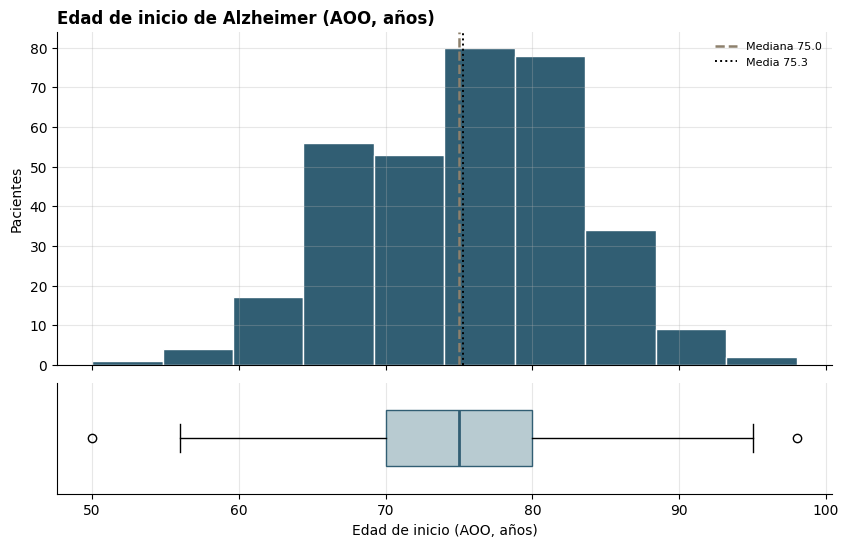

&nbsp;

**Coherencia de la AOO**

Casos marcados para revisión de coherencia: **16**

Estado,n
Sin inconsistencia,318
AOO no disponible,57
Inconsistente solo en hxgen,8
Inconsistente en ambas fuentes,5
Inconsistente solo en neuro,3


In [27]:
n_total = len(base_full)
n_aoo = base_full['aoo'].notna().sum()

subtitulo("Disponibilidad de la AOO")
mostrar_tabla(
    pd.DataFrame([{
        'cohorte_total': n_total,
        'AOO_disponible': n_aoo,
        'AOO_faltante': n_total - n_aoo,
        'disponibilidad_pct': round(100 * n_aoo / n_total, 1),
    }]),
    alto=100,
    renombrar={
        'cohorte_total': 'Cohorte total',
        'AOO_disponible': 'AOO disponible',
        'AOO_faltante': 'AOO faltante',
        'disponibilidad_pct': 'Disponibilidad (%)',
    },
    formato={'Disponibilidad (%)': '{:.1f}'},
    espacio=24,
    centrar=True
)

subtitulo("Resumen descriptivo")
renombrar = {
    'n_valido': 'Número de válidos',
    'n_faltante': 'Número de faltantes',
    'porcentaje_faltante': '% faltante',
    'media': 'Media',
    'mediana': 'Mediana',
    'DE': 'DE',
    'minimo': 'Mínimo',
    'Q1': 'Q1',
    'Q3': 'Q3',
    'maximo': 'Máximo',
    'RIQ': 'RIQ',
    'CV': 'CV',
}
mostrar_tabla(
    resumen_numerico(base_full['aoo']),
    alto=100,
    renombrar=renombrar,
    formato={'% faltante': '{:.1f}', 'Mínimo': '{:.0f}', 'Máximo': '{:.0f}'},
    espacio=24,
    centrar=True
)

subtitulo("Distribución de frecuencias")
renombrar = {
    'intervalo': 'Intervalo',
    'fi': 'Frecuencia absoluta (fi)',
    'hi': 'Frecuencia relativa (hi)',
    'Fi': 'Frecuencia acumulada (Fi)',
    'porcentaje_acumulado': 'Porcentaje acumulado (%)',
}
mostrar_tabla(
    tabla_frecuencias_numerica(base_full['aoo']),
    alto=300,
    renombrar=renombrar,
    formato={'Frecuencia relativa (hi)': '{:.3f}', 'Porcentaje acumulado (%)': '{:.1f}'},
    espacio=24,
    centrar=True
)

grafico_numerico_2(base_full['aoo'], 'Edad de inicio de Alzheimer (AOO, años)',
                   xlabel='Edad de inicio (AOO, años)')

n_incons = int(base_full['estado_consistencia_aoo'].str.startswith('Inconsistente', na=False).sum())
subtitulo("Coherencia de la AOO", espacio_antes=True)
display(Markdown(f"Casos marcados para revisión de coherencia: **{n_incons}**"))

mostrar_tabla(
    base_full['estado_consistencia_aoo']
    .value_counts(dropna=False)
    .rename_axis('estado')
    .reset_index(name='n'),
    alto=200,
    renombrar={'estado': 'Estado', 'n': 'n'},
    espacio=24,
    centrar=True
)

#### **Hallazgos principales**

La edad de inicio de la enfermedad de Alzheimer se concentra principalmente entre los 65 y 85 años, con una mayor frecuencia alrededor de los 75–83 años. La mediana se encuentra aproximadamente en 75 años y el 50 % central de los pacientes presenta edades de inicio entre cerca de 70 y 80 años, lo que se observa también en el boxplot. La distribución no presenta una asimetría marcada, aunque existen observaciones en los extremos de aproximadamente 50 y 98 años. Estos valores extremos no se eliminan automáticamente, ya que en el contexto del estudio pueden representar pacientes con inicio particularmente temprano o tardío y, por tanto, podrían ser relevantes para el posterior análisis de variantes genéticas modificadoras de la edad de inicio. Adicionalmente, se identificaron 15 casos marcados para revisión de coherencia entre la AOO y las edades registradas en las fuentes disponibles.

<br>

## **5. Variables sociodemográficas**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
genero,Femenino,259,66.8,3
IDIOMA,Español,388,100.0,3
Nivel educativo,Primaria,182,48.1,4
Estado civil,Casado,158,43.4,3
Estado Habitacional,"Vive con otra persona: familiar, amigo o compañero de cuarto",119,31.2,3
Nivel de independencia,Requiere asistencia para actividades complejas,209,54.1,4
Tipo de residencia,"Residencia privada (departamento, condominio, casa)",327,84.5,4
Lateralidad,Diestro,383,99.0,3


**Distribuciones**

Variables integradas en la familia: **11** · graficadas: **9** · resumidas sin gráfico: **2**

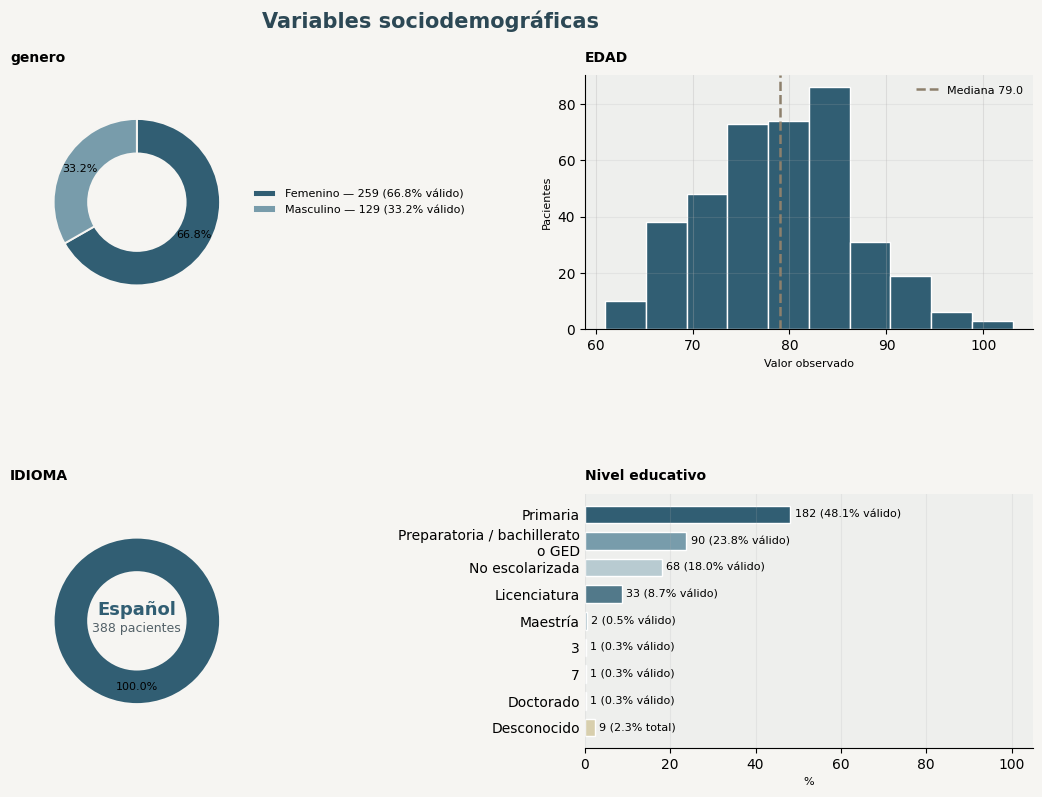

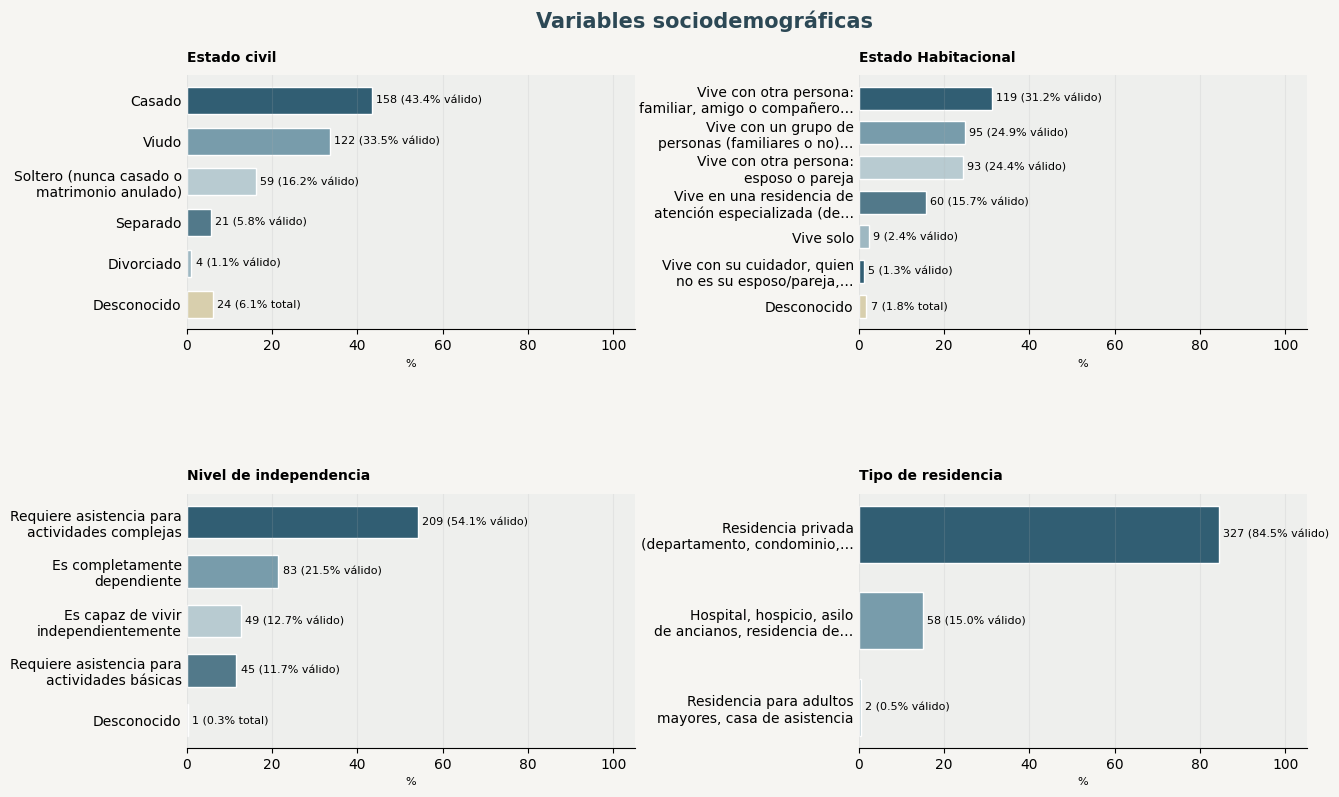

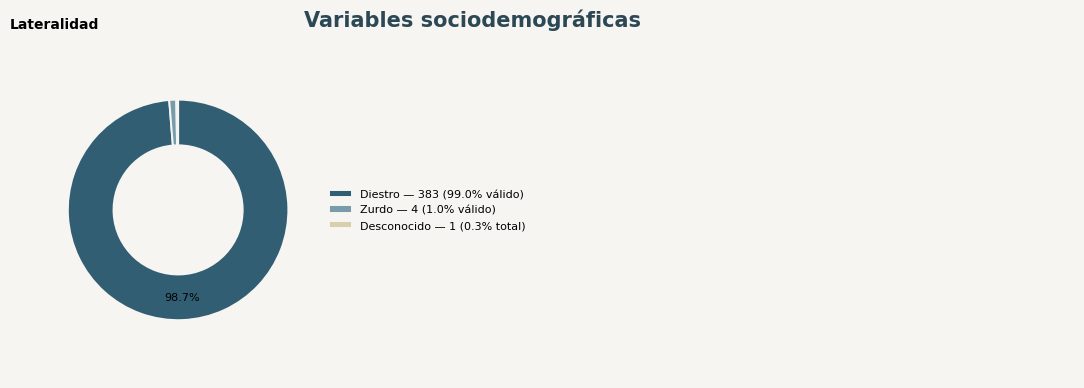

&nbsp;

**Variables no graficadas por alta cardinalidad o tipo de dato**

Variable,Tipo,n válido,Faltantes,n únicos
mes y año de nacimiento,texto libre / alta cardinalidad,387,4,374
OTRO IDOMA,texto libre / alta cardinalidad,388,3,3


In [28]:
from functools import partial

serie_univ = partial(serie_univariada, inventario=inventario, base_full=base_full,
                     CODIGO_NO_REGISTRADO=CODIGO_NO_REGISTRADO,
                     ETIQUETA_NO_REGISTRADO=ETIQUETA_NO_REGISTRADO)
etiqueta = partial(etiqueta_bonita, inventario=inventario)

s = serie_univ(col)
nombre = etiqueta(col)

columnas = inventario.loc[
    (inventario["familia"] == "sociodemograficas") &
    (~inventario["tipo_analitico"].isin(["identificador", "variable auxiliar del EDA"])),
    "columna"
].tolist()

resumen_cat = []
for col in columnas:
    fila = inventario.loc[inventario["columna"].eq(col)]
    if fila.empty:
        continue
    tipo = fila["tipo_analitico"].iloc[0]
    if tipo not in ["categórica nominal", "categórica binaria", "ordinal"]:
        continue

    s = serie_univariada(col, inventario, base_full,
                         CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)
    t = tabla_cat(s)
    if t.empty:
        continue

    # Categoría predominante entre los valores válidos (sin Desconocido/No registrado)
    validas = t.loc[~t["especial"]]
    principal = validas.iloc[0] if len(validas) > 0 else t.iloc[0]

    resumen_cat.append({
        "variable": etiqueta_bonita(col, inventario),
        "categoría predominante": principal["categoria"],
        "n": int(principal["n"]),
        "% válido": round(principal["pct"], 1),
        "faltantes": int(s.isna().sum()),
    })

subtitulo("Resumen de variables categóricas")
if resumen_cat:
    mostrar_tabla(
        pd.DataFrame(resumen_cat),
        alto=350,
        renombrar={
            "variable": "Variable",
            "categoría predominante": "Categoría predominante",
            "n": "n",
            "% válido": "% válido",
            "faltantes": "Faltantes",
        },
        formato={"% válido": "{:.1f}"},
        ajustar_texto=True,
        una_linea=["Variable", "n", "% válido", "Faltantes"],
        anchos={"Categoría predominante": 380},
        espacio=24,
        centrar=True
    )
else:
    display(Markdown("No se identificaron variables categóricas en esta familia."))

subtitulo("Distribuciones")
analisis_familia(
    columnas, inventario, base_full, "Variables sociodemográficas",
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO
)

#### **Hallazgos principales**

La cohorte presenta una distribución etaria concentrada principalmente entre los 70 y 85 años, con una mediana cercana a los 79 años, lo que confirma que se trata mayoritariamente de una población adulta mayor. En la variable género, la categoría codificada como 1 concentra aproximadamente dos tercios de los registros válidos (66,8%), mientras que la categoría 0 representa el 33,2%; la interpretación sustantiva de estas categorías debe realizarse una vez se confirme su codificación. El nivel educativo muestra una fuerte concentración en unas pocas categorías, especialmente en los valores 5 y 12, mientras que otras categorías presentan frecuencias muy bajas. De forma similar, el estado civil, el estado habitacional, el nivel de independencia y el tipo de residencia presentan distribuciones desiguales, con una o dos categorías claramente predominantes. En lateralidad se observa una concentración casi total en la categoría 2 (98,7%), lo que indica una variabilidad mínima en esta variable dentro de la cohorte. Dado que varias de estas variables están codificadas numéricamente, estos resultados se interpretan por ahora en términos de distribución de categorías y no de su significado clínico o social hasta validar el diccionario de códigos con el investigador.

<br>

## **6. Informante y red de apoyo**

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
Relación del Informante,"Hijo (consanguíneo, hijastro, adoptado)",172,44.3,3
¿Vive el informante con el sujeto?,Sí,261,81.6,4
"Si el informante no vive con el sujeto, ¿con qué frecuencia visita personalmente al sujeto?",Diario,242,91.7,5
"Si el informante no vive con el sujeto, ¿con qué frecuencia tiene contacto telefónico con él?",Diario,246,93.2,5


**Distribuciones**

Variables integradas en la familia: **5** · graficadas: **5** · resumidas sin gráfico: **0**

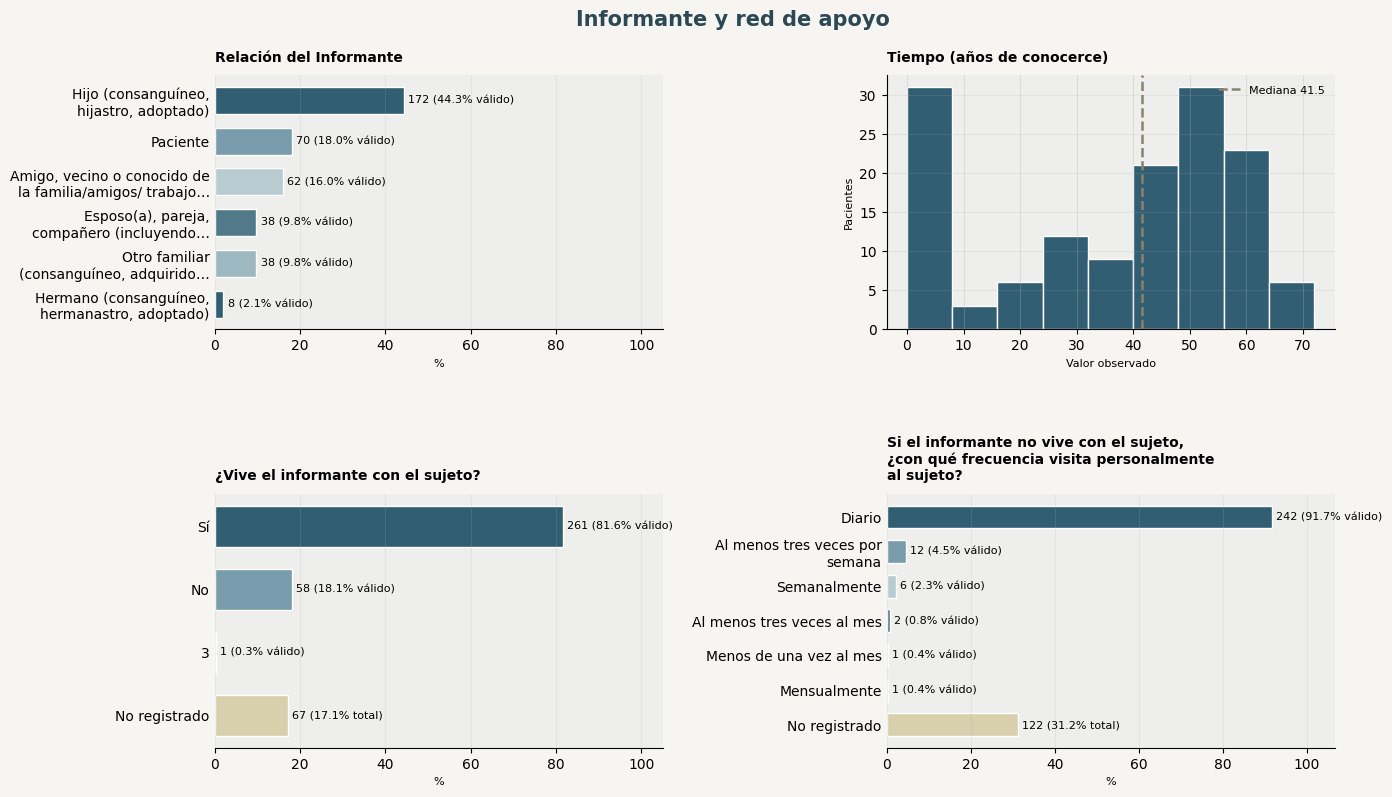

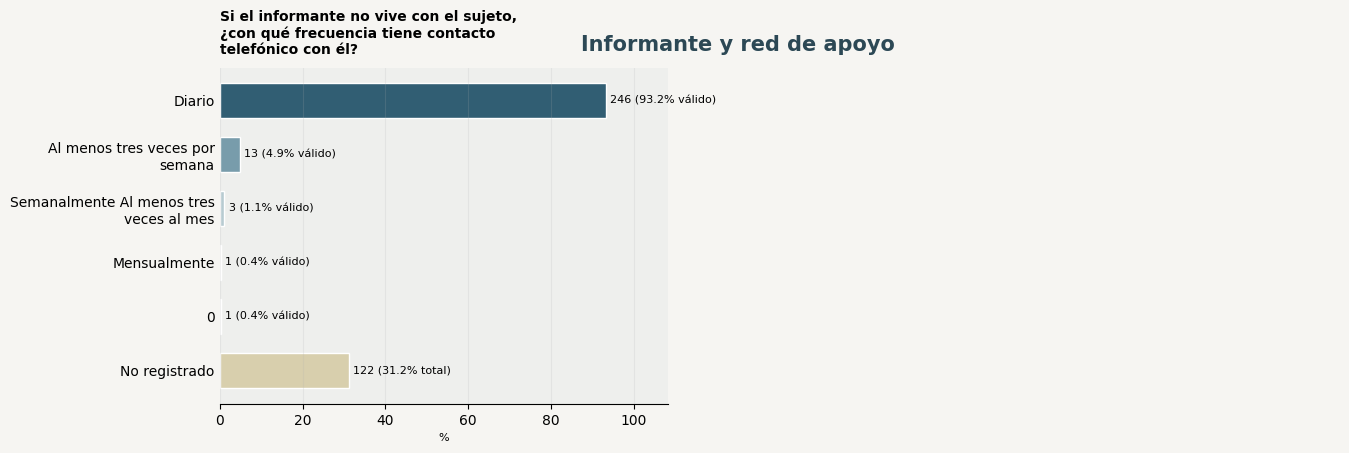

In [29]:
ejecutar_familia("informante_red_apoyo", "Informante y red de apoyo",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

La información disponible muestra que la relación del informante con el participante se concentra principalmente en la categoría 2, que representa el 44,6% de los registros válidos, seguida por las categorías 6 y 5. En cuanto a la convivencia, la categoría 1 concentra el 67,3% de los registros válidos, mientras que el 15,1% corresponde a la categoría 0; además, aparece una proporción importante de registros que no indican. Entre los casos en los que se reporta que el informante no vive con el sujeto, la categoría 1 es la más frecuente tanto para las visitas personales (62,5%) como para el contacto telefónico (63,5%). Sin embargo, la interpretación sustantiva de estas categorías debe quedar pendiente hasta validar con el investigador qué significa cada código.

<br>

## **7. Historia familiar**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.



**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
"¿Hay miembros afectados de la familia (padres biológicos, hermanos consanguíneos completos (comparten ambos padres), o hijos biológicos)?",No,233,63.3,5
Familiar afectado,0,59,31.1,4


**Distribuciones**

Variables integradas en la familia: **2** · graficadas: **2** · resumidas sin gráfico: **0**

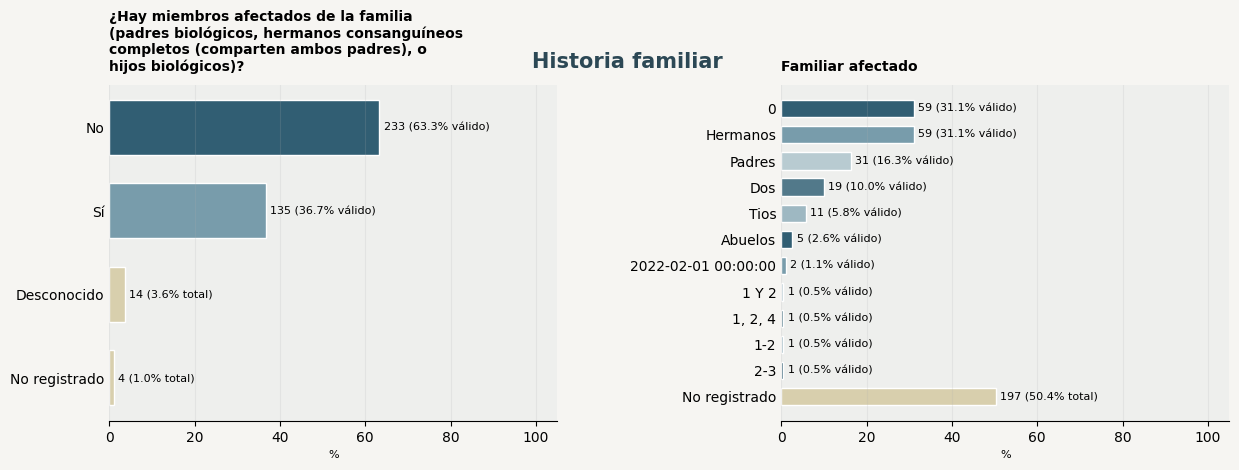

In [30]:
ejecutar_familia("historia_familiar","Historia familiar",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

En la variable sobre presencia de familiares biológicos afectados, la categoría 0 concentra el 60,2% de los registros y la categoría 1 el 34,9%. También aparecen algunos registros codificados como 9, NO y -; en este último caso, el guion corresponde a información no registrada para el paciente. En la variable Familiar afectado, el 50,9% de los registros no cuenta con información registrada, mientras que entre los casos con dato disponible predominan las categorías 0 y 2, cada una con 15,3%. Dado que esta información puede ser relevante para el componente genético del estudio, conviene validar el significado de los demás códigos y homologar las categorías antes de realizar análisis asociativos.

<br>

## **8. Antropometría**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.



**Distribuciones**

Variables integradas en la familia: **2** · graficadas: **2** · resumidas sin gráfico: **0**

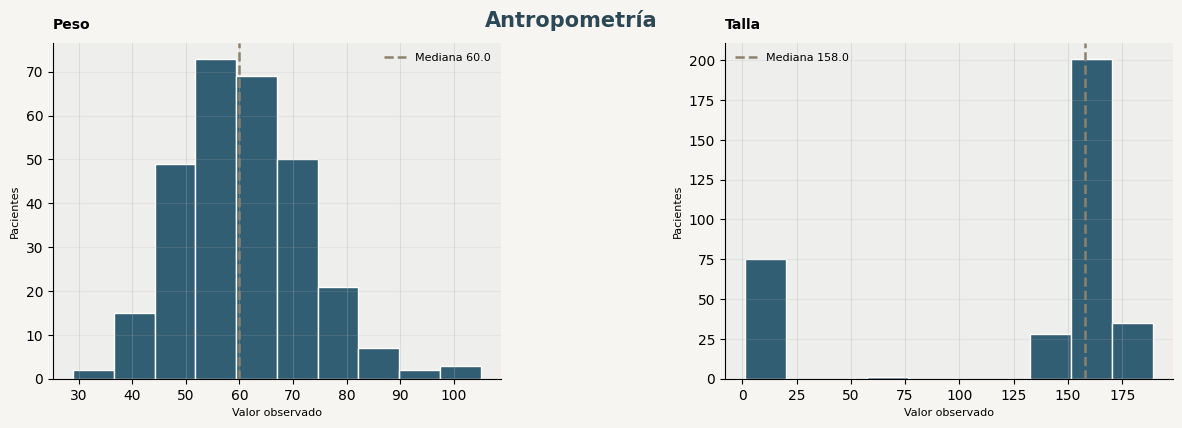

In [31]:
ejecutar_familia("antropometria","Antropometría",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

El peso presenta una distribución unimodal, con mayor concentración aproximadamente entre 50 y 75 kg y una mediana de 60 kg. La mayor parte de los pacientes se agrupa alrededor de valores intermedios, aunque se observan algunos registros en los extremos bajos y altos que conviene revisar individualmente antes de decidir si corresponden a valores reales o posibles errores de registro.

En la talla, la mediana se sitúa en 158 cm y la mayoría de los registros se concentra aproximadamente entre 145 y 175 cm. Sin embargo, la distribución muestra un grupo separado de valores muy bajos, cercanos a 0–20, claramente incompatibles con el rango esperado si toda la variable estuviera expresada en centímetros. Esto sugiere una posible mezcla de unidades, por ejemplo registros en metros y otros en centímetros, o errores de digitación. Antes de utilizar la talla en análisis posteriores, es necesario revisar y homogeneizar la unidad de medida.

<br>

## **9. Medicamentos**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

In [32]:
ejecutar_familia("medicamentos","Medicamentos",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

**Distribuciones**

Variables integradas en la familia: **9** · graficadas: **0** · resumidas sin gráfico: **9**

&nbsp;

**Variables no graficadas por alta cardinalidad o tipo de dato**

Variable,Tipo,n válido,Faltantes,n únicos
MEDICAMENTO DEL SUJETO 1,texto libre / alta cardinalidad,386,5,83
MEDICAMENTO DEL SUJETO 2,texto libre / alta cardinalidad,385,6,101
MEDICAMENTO DEL SUJETO 3,texto libre / alta cardinalidad,385,6,70
MEDICAMENTO DEL SUJETO 4,texto libre / alta cardinalidad,386,5,64
MEDICAMENTO DEL SUJETO 5,texto libre / alta cardinalidad,386,5,47
MEDICAMENTO DEL SUJETO 6,texto libre / alta cardinalidad,386,5,33
MEDICAMENTO DEL SUJETO 7,texto libre / alta cardinalidad,386,5,23
MEDICAMENTO DEL SUJETO 8,texto libre / alta cardinalidad,386,5,15
MEDICAMENTO DEL SUJETO 9,texto libre / alta cardinalidad,385,6,15


#### **Hallazgos principales**

Las variables de medicamentos presentan una alta cardinalidad, especialmente en las primeras posiciones del registro. El primer medicamento tiene 86 valores únicos y el segundo 103, mientras que la diversidad disminuye progresivamente hasta 15 valores únicos en los medicamentos 8 y 9. Esto indica que no es conveniente analizar cada columna como una variable categórica convencional mediante gráficos de barras, porque se generarían demasiadas categorías y la interpretación sería poco útil.

Además, en varias posiciones el valor modal es -, que en esta base corresponde a información no registrada para el paciente. En el primer medicamento, en cambio, el valor más frecuente registrado es losartán, lo que sugiere que este fármaco aparece con relativa frecuencia dentro de la cohorte. Sin embargo, estas columnas deben interpretarse con cautela, ya que la posición “Medicamento 1”, “Medicamento 2”, etc. no representa necesariamente una categoría clínica distinta, sino diferentes espacios disponibles para registrar tratamientos.

<br>

## **10. Tabaquismo y hábitos**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

Para los años de tabaquismo, el código 99 se presenta como faltante en la vista univariada. Se mantiene sin cambios la columna original.

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
El sujeto ha fumado en los pasados 30 días,No,374,98.9,3
¿El sujeto ha fumado más de 100 cigarros / cigarrillos en su vida?,No,276,74.0,3


**Distribuciones**

Variables integradas en la familia: **3** · graficadas: **3** · resumidas sin gráfico: **0**

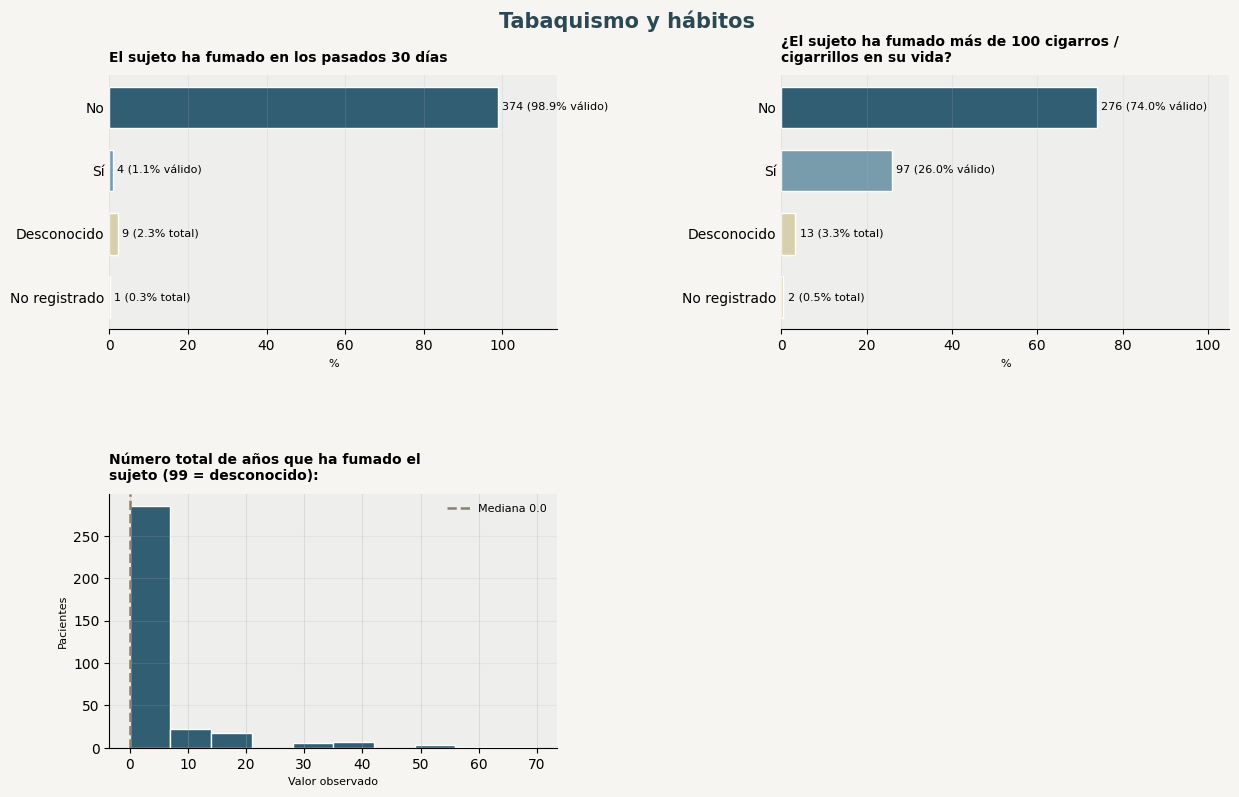

In [33]:
ejecutar_familia("tabaquismo","Tabaquismo y hábitos",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

En relación con el tabaquismo reciente, la gran mayoría de los participantes se encuentra en la categoría 0 (96,4%), mientras que la categoría 1 representa solo el 1,0%. La categoría 9 corresponde a desconocido y el símbolo - a dato no registrado, por lo que ambos deben tratarse como información faltante y no como categorías clínicas.

Para el antecedente de haber fumado más de 100 cigarrillos a lo largo de la vida, el 71,0% está en la categoría 0 y el 25,1% en la categoría 1, mientras que el 3,4% corresponde a 9 = desconocido. Esto sugiere que, aunque el tabaquismo reciente es poco frecuente, sí existe una proporción mayor con antecedente histórico de consumo.

En la variable número total de años fumados, la mediana es 0 años y la distribución está fuertemente concentrada en cero, con una cola hacia valores altos. El código 99 también representa desconocido, por lo que debe recodificarse como faltante antes de cualquier análisis cuantitativo.

<br>

## **11. Antecedentes cardiovasculares y cerebrovasculares**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
Ataque cardiaco o paro cardíaco,No,381,98.4,3
Fibrilación auricular,0,381,98.4,4
Angioplastía/ endarterectomía/ stent,0,388,100.0,3
Bypass cardíaco/coronario,0,388,100.0,3
Marcapasos y/o desfibrilador,0,383,98.7,3
Insuficiencia cardíaca congestiva,0,384,99.2,4
ENFERMEDAD CEREBRO-VASCULAR (ECV),0,377,97.4,4


**Distribuciones**

Variables integradas en la familia: **7** · graficadas: **7** · resumidas sin gráfico: **0**

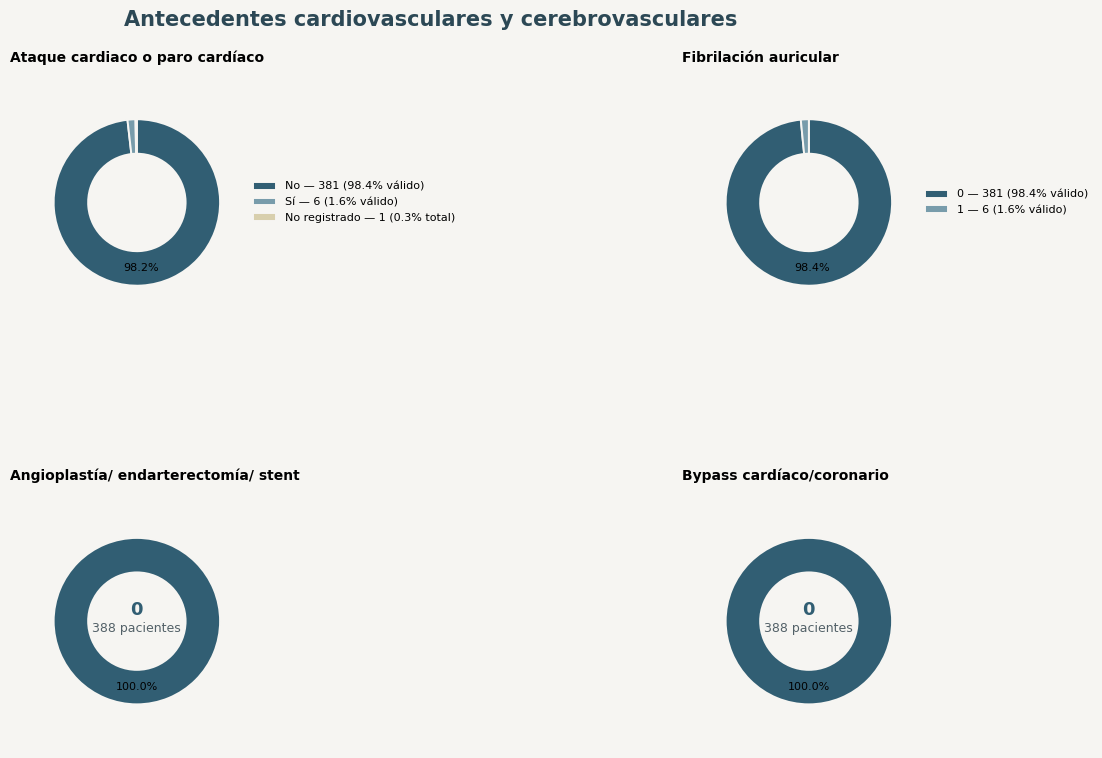

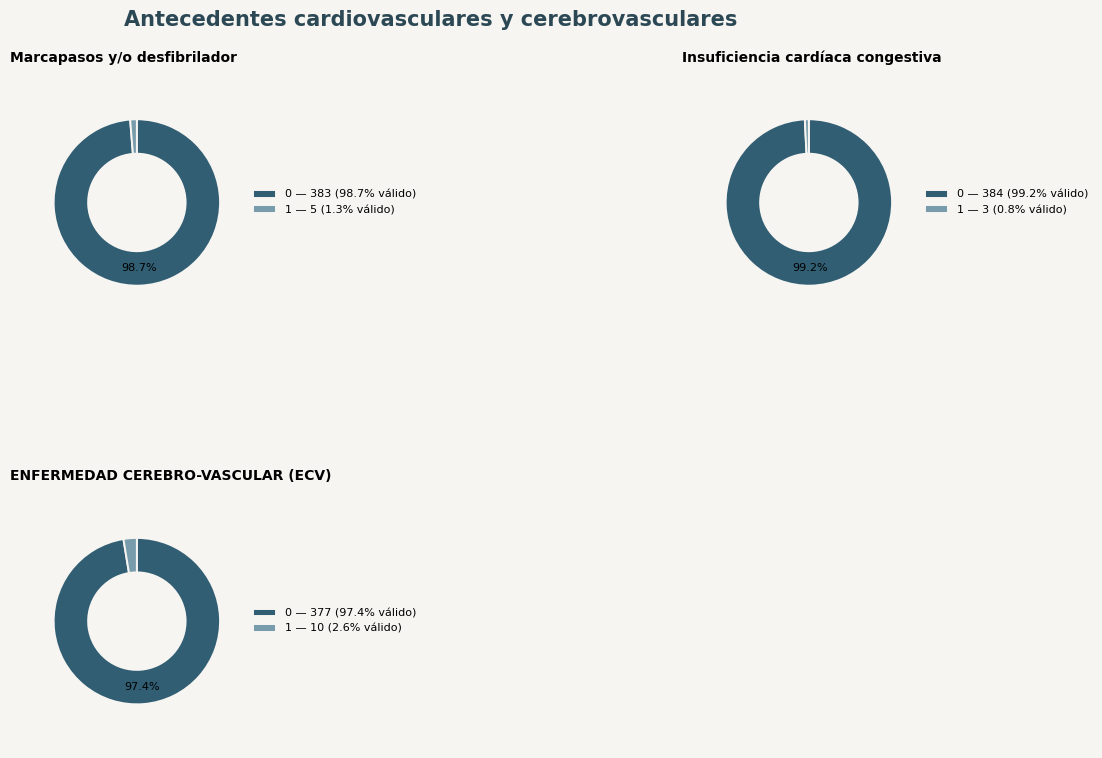

In [34]:
ejecutar_familia("cardiovasculares_cerebrovasculares","Antecedentes cardiovasculares y cerebrovasculares",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

Los antecedentes cardiovasculares y cerebrovasculares presentan una frecuencia baja en la cohorte. El antecedente de ataque cardíaco o paro cardíaco aparece en 6 pacientes (1,6%), al igual que la fibrilación auricular. Los procedimientos de angioplastia, endarterectomía o stent, así como el bypass cardíaco/coronario, no presentan casos positivos registrados en los datos disponibles, por lo que estas variables no muestran variabilidad en la cohorte. El uso de marcapasos o desfibrilador se registra en 5 pacientes (1,3%), mientras que la insuficiencia cardíaca congestiva aparece en 3 pacientes (0,8%). La enfermedad cerebrovascular es el antecedente más frecuente dentro de este grupo, con 10 pacientes (2,6%).

En conjunto, estas variables muestran prevalencias muy bajas, por lo que su capacidad para discriminar diferencias entre pacientes o aportar potencia estadística en análisis posteriores puede ser limitada. Además, en algunas variables aparece -, que corresponde a un dato no registrado y debe tratarse como faltante, no como ausencia del antecedente.

<br>

## **12. Antecedentes neurológicos**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
PARKINSON,0,385,99.5,4
CONVULSIONES,0,384,99.0,3
TRAUMATISMO DE CRÁNEO-ENCEFÁLICO (TCE),0,388,100.0,3


**Distribuciones**

Variables integradas en la familia: **3** · graficadas: **3** · resumidas sin gráfico: **0**

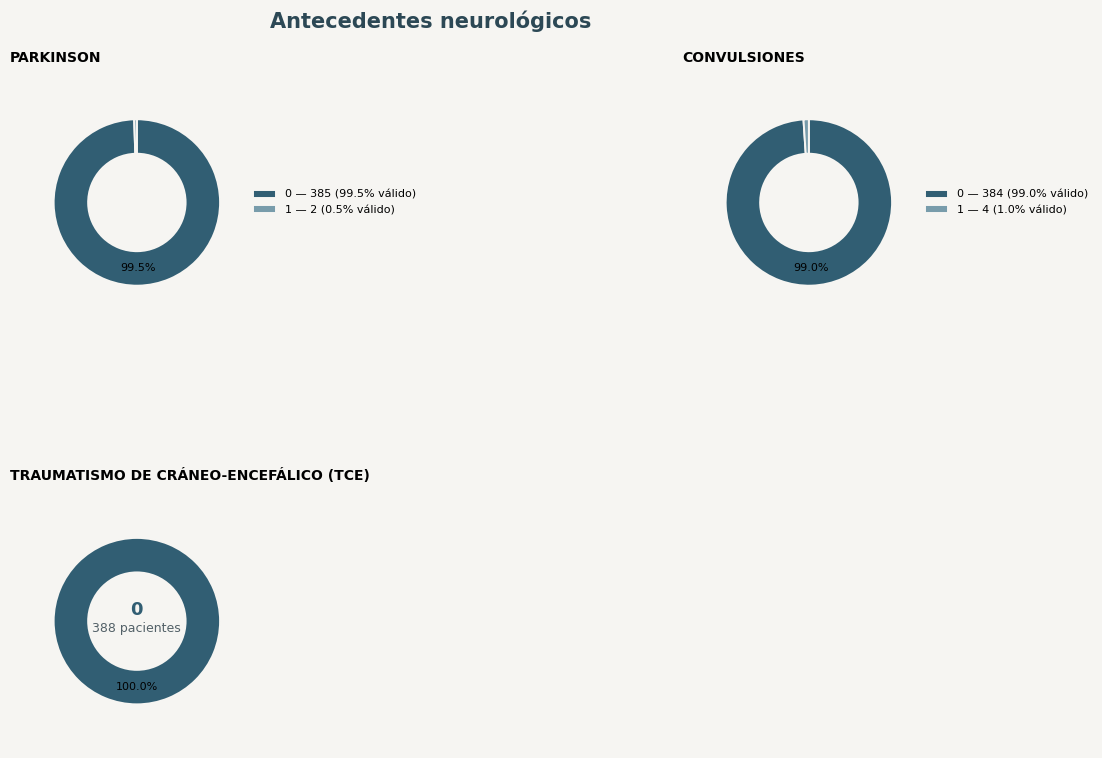

In [35]:
ejecutar_familia("neurologicos","Antecedentes neurológicos",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

Los antecedentes neurológicos son poco frecuentes en la cohorte. El antecedente de Parkinson aparece en 2 pacientes (0,5%) y las convulsiones en 4 pacientes (1,0%). En cuanto al traumatismo craneoencefálico, todos los registros disponibles se encuentran en la categoría 0, por lo que no presenta variabilidad dentro de la muestra analizada.

En conjunto, estas variables aportan principalmente a la caracterización clínica, pero su baja frecuencia limita su capacidad para diferenciar subgrupos o aportar potencia estadística en análisis posteriores. En particular, una variable completamente constante, como el antecedente de TCE en esta cohorte, no podría contribuir a explicar diferencias en AOO dentro de un modelo.

<br>

## **13. Comorbilidades y condiciones médicas**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
DIABETES,No,325,84.2,3
CANCER,0,380,98.2,4
Hipercholesterolemia,0,383,99.2,5
Hipertensión arterial,1,213,55.0,4
NIVELES DE VITAMINA D,0,388,100.0,3
Deficiencia de B12,0,387,99.7,3
Enfermedad tiroidea,0,365,94.1,3
Artritis,0,386,99.5,3
Artrosis,0,363,93.6,3
Osteoporosis,0,378,97.4,3


**Distribuciones**

Variables integradas en la familia: **13** · graficadas: **13** · resumidas sin gráfico: **0**

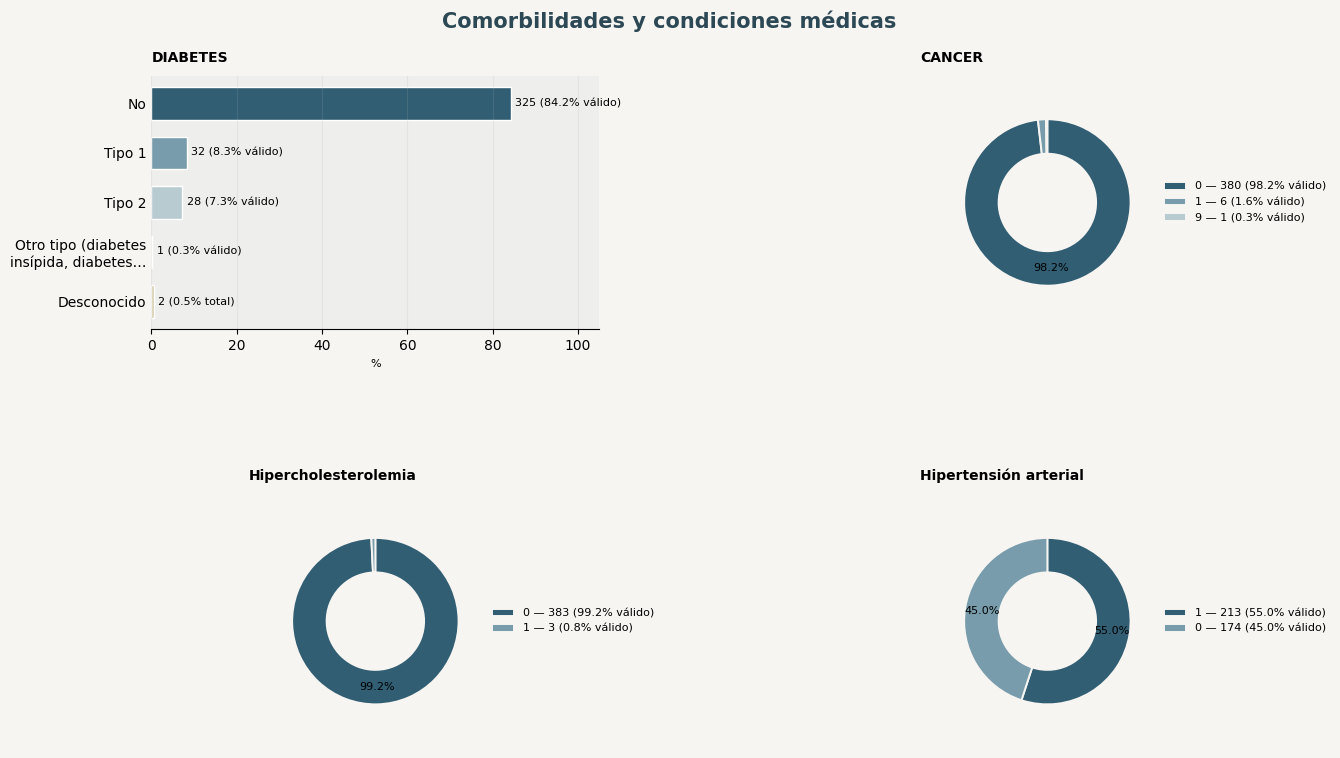

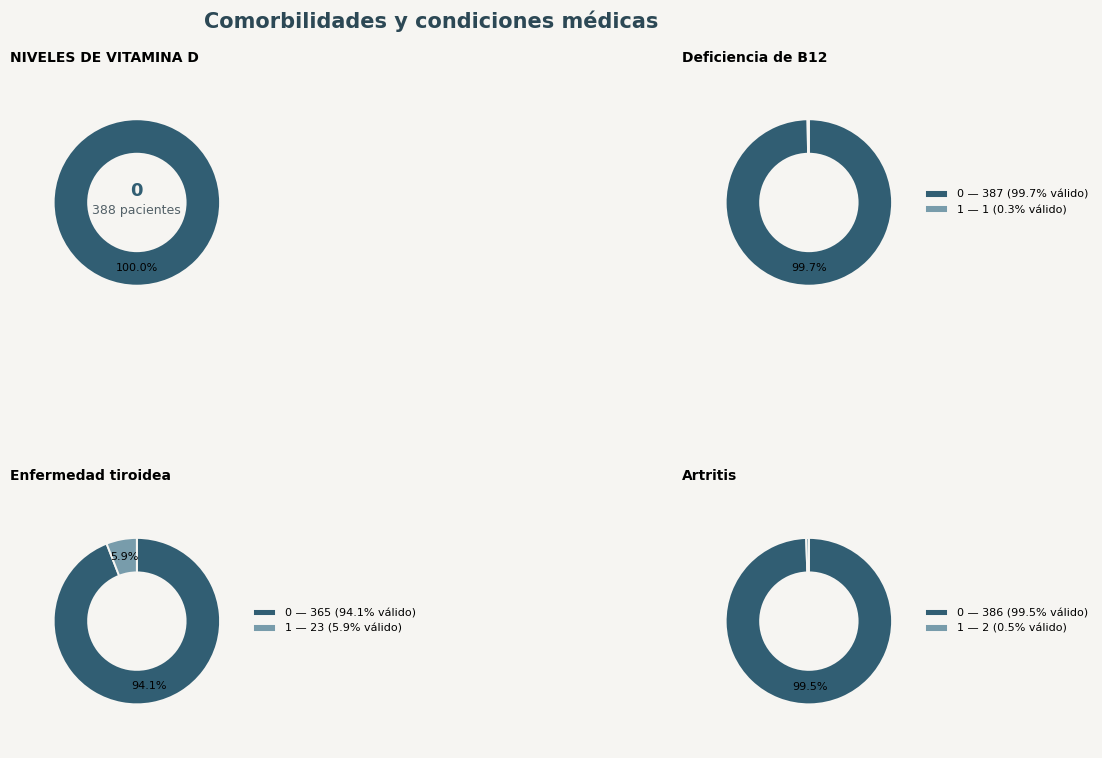

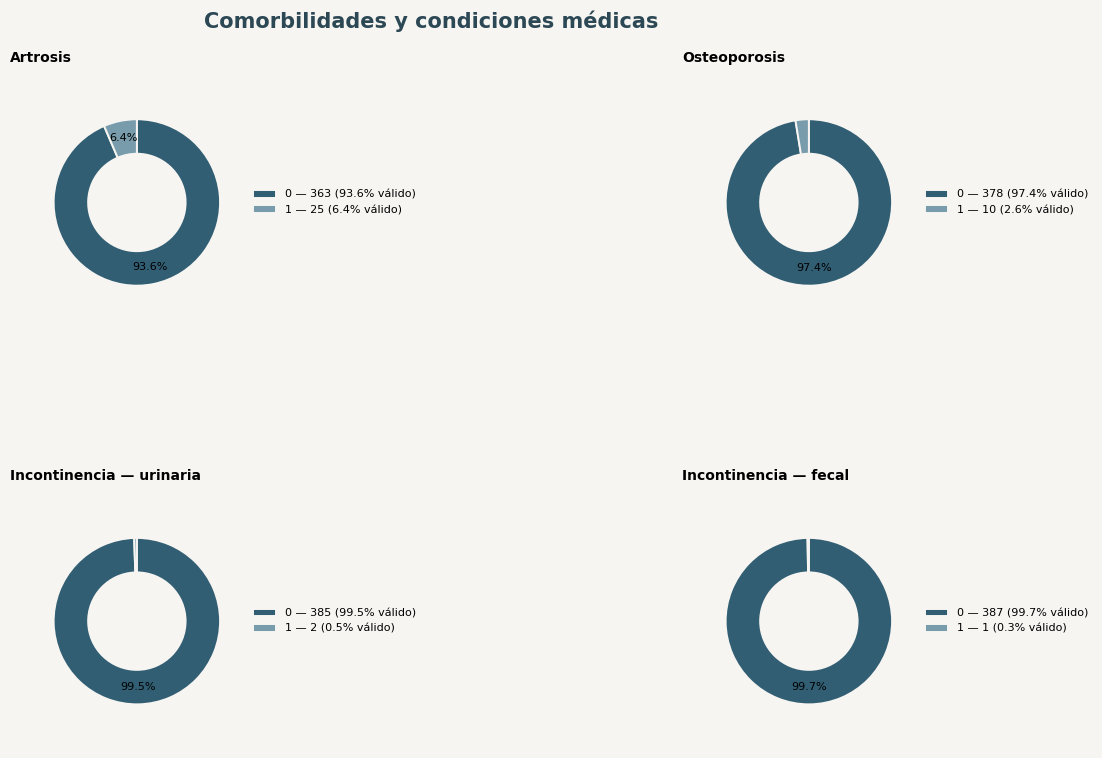

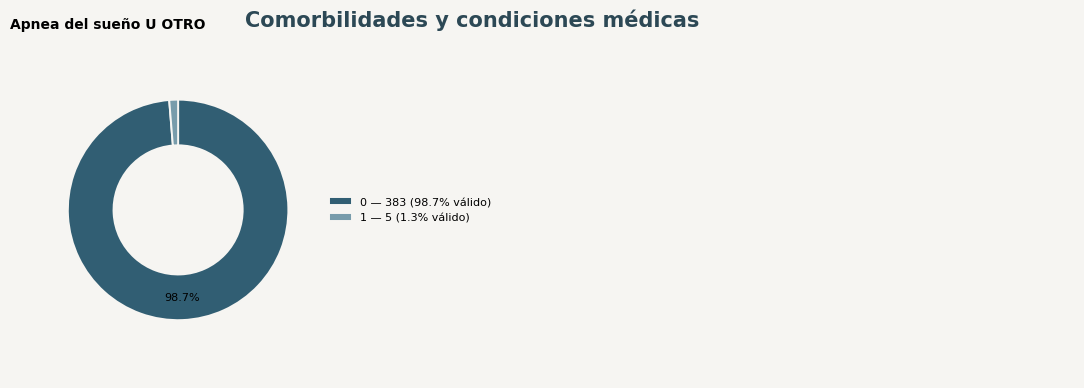

In [36]:
ejecutar_familia("metabolicos_otros","Comorbilidades y condiciones médicas",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

Dentro del grupo de comorbilidades y condiciones médicas, la hipertensión arterial destaca claramente como la condición más frecuente: la categoría 1 representa el 54,8% de los registros válidos, frente al 45,2% en la categoría 0. Esto indica que, a diferencia de muchas otras comorbilidades, la hipertensión sí presenta una frecuencia alta y suficiente variabilidad dentro de la cohorte.

La diabetes muestra una distribución más heterogénea: la categoría 0 concentra el 83,9%, mientras que las categorías 1 y 2 representan el 8,3% y 7,0%, respectivamente. También aparecen los códigos 9 y 3 en proporciones muy bajas. Dado que 9 corresponde a desconocido, y el significado clínico de 1, 2 y 3 debe confirmarse, esta variable requiere validación de su codificación antes de interpretarla como una condición binaria.

El resto de las comorbilidades presenta frecuencias mucho menores. El cáncer aparece en 1,6% de los registros, la hipercolesterolemia en 0,8%, la deficiencia de vitamina B12 en 0,3%, la enfermedad tiroidea en 6,0%, la artritis en 0,5%, la artrosis en 6,5%, la osteoporosis en 2,6%, la incontinencia urinaria en 0,5%, la incontinencia fecal en 0,3% y la apnea del sueño u otra condición relacionada en 1,3%. Los niveles de vitamina D aparecen sin variabilidad, con todos los registros disponibles en la categoría 0.

En conjunto, salvo hipertensión y en menor medida diabetes, enfermedad tiroidea y artrosis, la mayoría de estas variables son poco frecuentes o casi constantes. Esto limita su capacidad para diferenciar subgrupos dentro de la cohorte y su utilidad potencial en análisis posteriores. Además, cualquier uso de estas comorbilidades como covariables de AOO debe considerar primero su temporalidad respecto al inicio del Alzheimer, ya que si fueron registradas después del inicio de la enfermedad podrían introducir riesgo de leakage.

<br>

## **14. Antecedentes psiquiátricos**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
Trastorno de estrés postraumático (TEPT),0,387,100.0,4
Trastorno bipolar,0,388,100.0,3
Esquizofrenia,0,384,99.2,4
Depresión,0,379,97.9,4
Ansiedad,0,382,98.5,3
Trastorno obsesivo-compulsivo (TOC),0,388,100.0,3
"Trastornos neuropsiquiátricos del desarrollo (por ejemplo, trastorno del espectro autista (TEA), déficit de atención con hiperactividad (TDAH), dislexia)",0,388,100.0,3


**Distribuciones**

Variables integradas en la familia: **7** · graficadas: **7** · resumidas sin gráfico: **0**

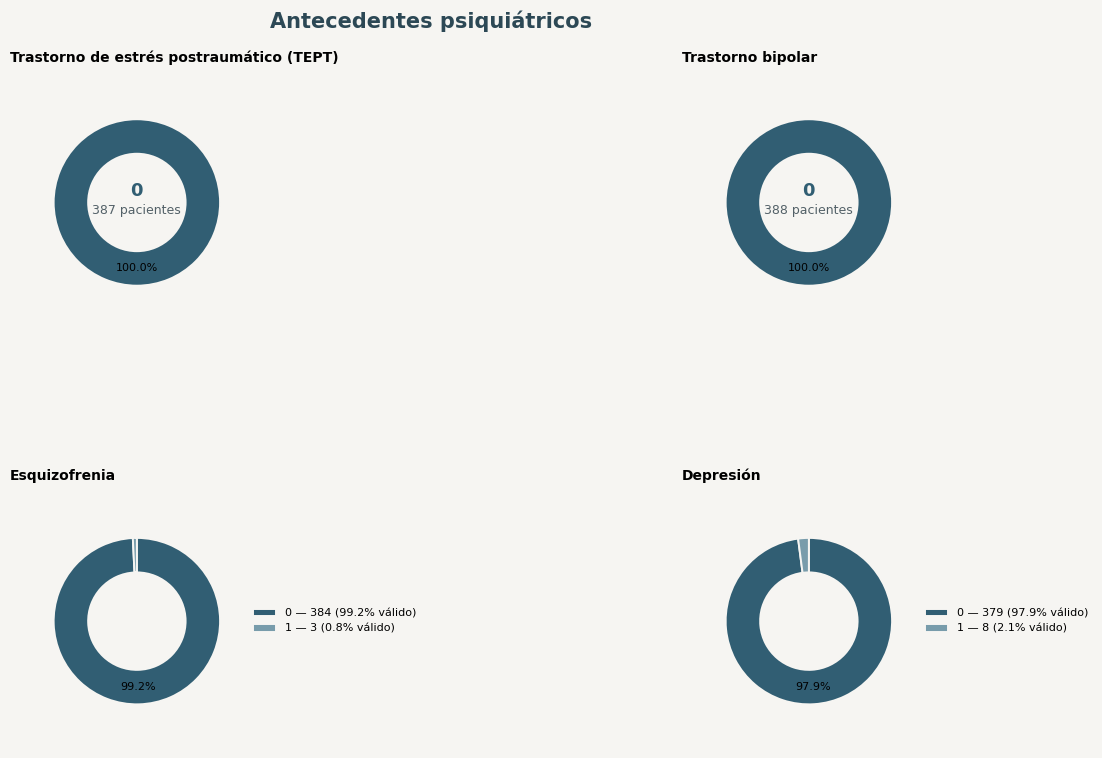

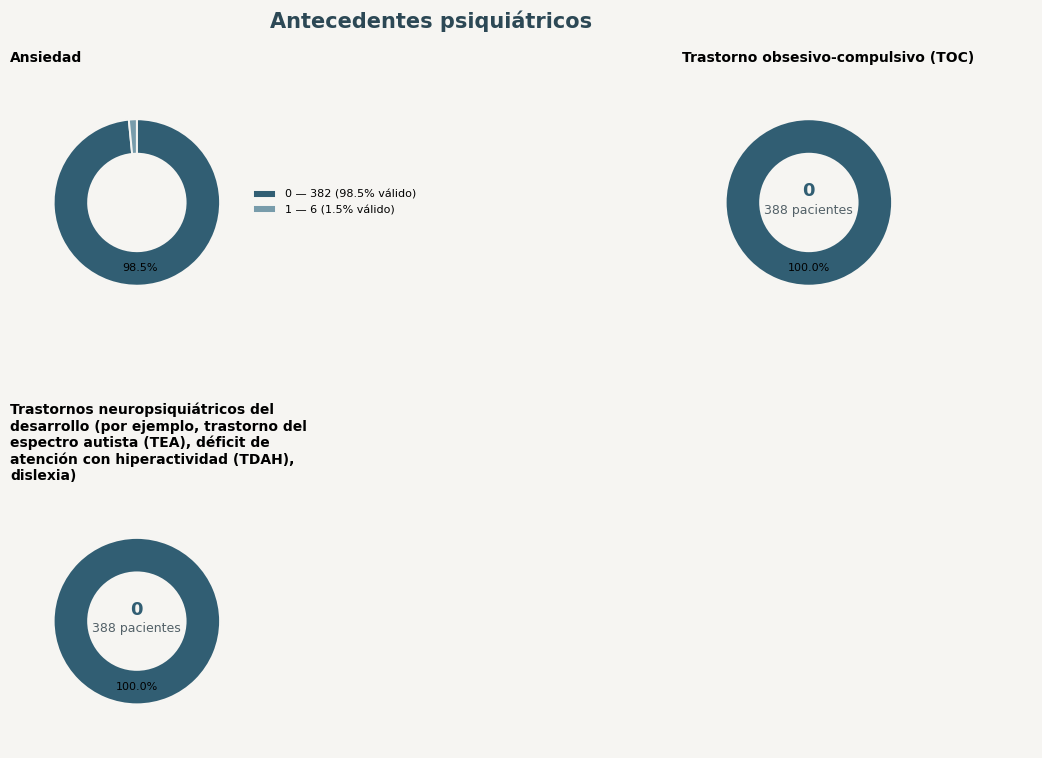

In [37]:
ejecutar_familia("psiquiatricos","Antecedentes psiquiátricos",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

Los antecedentes psiquiátricos son poco frecuentes en la cohorte. No se registran casos positivos de trastorno de estrés postraumático, trastorno bipolar, trastorno obsesivo-compulsivo ni trastornos neuropsiquiátricos del desarrollo en los datos disponibles, por lo que estas variables no presentan variabilidad dentro de la muestra. La esquizofrenia aparece en 3 pacientes (0,8%), la depresión en 8 pacientes (2,1%) y la ansiedad en 6 pacientes (1,6%).

En conjunto, estas condiciones aportan principalmente a la caracterización clínica, pero su baja frecuencia limita su capacidad para diferenciar subgrupos o contribuir de manera importante a análisis posteriores. Además, al igual que con otras comorbilidades, antes de utilizarlas como covariables de AOO debe confirmarse si corresponden a antecedentes previos al inicio del Alzheimer o a condiciones registradas durante una evaluación posterior.

<br>

## **15. Variables clínicas HXGEN**

La interpretación como covariable anterior al inicio requiere validar la temporalidad cuando corresponda. Se conservan los códigos originales cuando su significado no está documentado.

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
¿Actualmente se encuentra en algún tratamiento farmacológico?,Sí,322,82.6,1
¿Usted fuma?,No,384,98.2,0
¿Con que frecuencia consume alcohol?,Nunca,360,92.5,2
¿Le han realizado algún procedimiento quirúrgico?,No,318,81.3,0
¿Sufre de algún tipo de alergia?,No,379,96.9,0
Si la respuesta anterior es SI. ¿A que es alérgico?,Atópica,1,8.3,379
¿Alguien más en su familia tiene o tuvo Alzheimer?,No,215,61.8,43


**Distribuciones**

Variables integradas en la familia: **23** · graficadas: **10** · resumidas sin gráfico: **13**

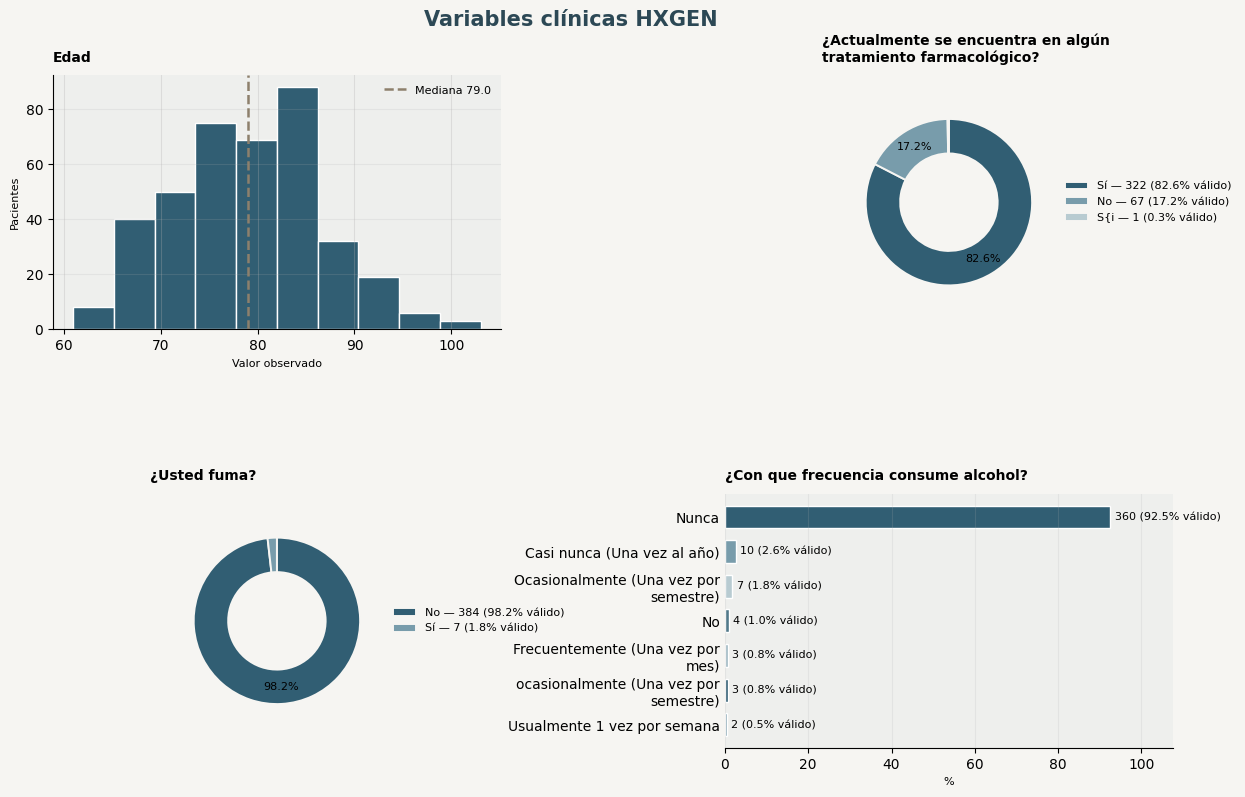

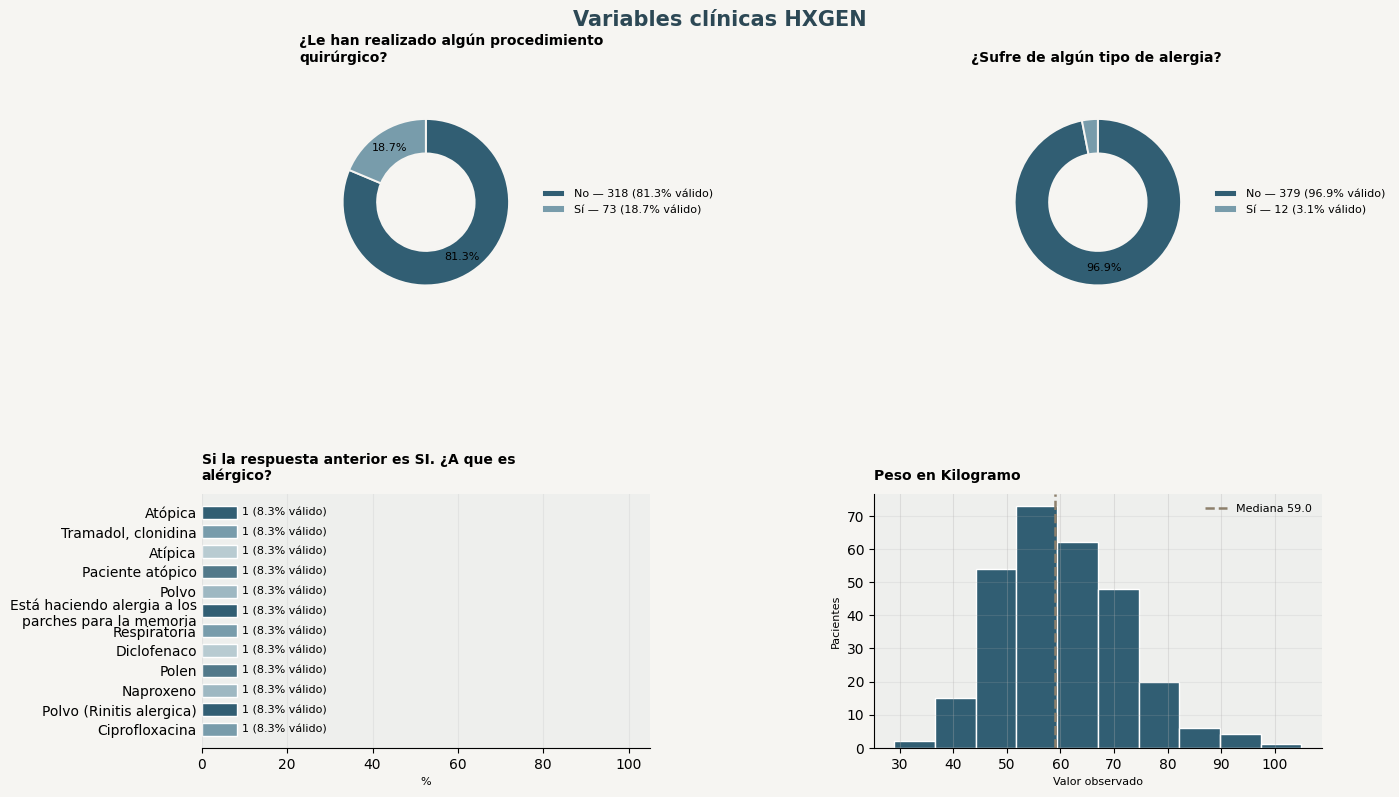

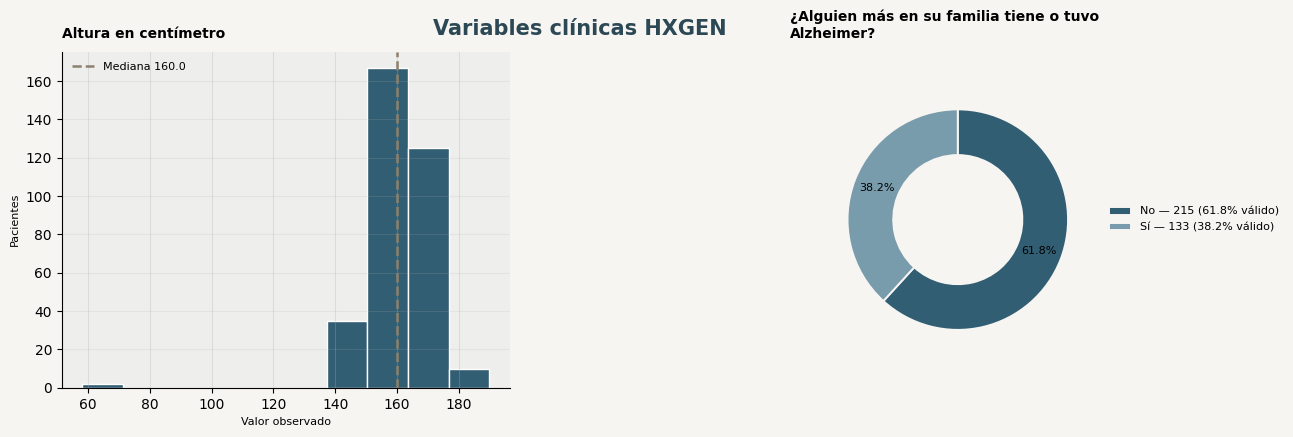

&nbsp;

**Variables no graficadas por alta cardinalidad o tipo de dato**

Variable,Tipo,n válido,Faltantes,n únicos
Ciudad o municipio de residencia,texto libre / alta cardinalidad,391,0,78
Enfermedad actual,texto libre / alta cardinalidad,391,0,5
¿Qué síntomas presenta?,texto libre / alta cardinalidad,391,0,88
El Paciente necesita apoyo para realizar las siguientes tareas,texto libre / alta cardinalidad,380,11,38
Indique que estudios previos le han realizado.,texto libre / alta cardinalidad,384,7,24
"Si le han realizado estudios previos, ¿Encontraron hallazgos? ¿Cuales?",texto libre / alta cardinalidad,374,17,33
Antecedentes,texto libre / alta cardinalidad,299,92,105
"Si la respuesta anterior fue SI, ¿Qué medicamentos está consumiendo?",texto libre / alta cardinalidad,323,68,284
"Si respuesta anterior fue afirmativa, ¿Hace cuantos años fuma?",texto libre / alta cardinalidad,15,376,15
Si la respuesta anterior fue SI. ¿Qué cirugía le han realizado?,texto libre / alta cardinalidad,75,316,62


In [38]:
ejecutar_familia("historia_clinica_genetica","Variables clínicas HXGEN",
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

HXGEN tiene información clínica muy rica, pero aquí el hallazgo más importante es de calidad de datos: muchas respuestas equivalentes están escritas de formas distintas, por ejemplo Sí, SI, Si, si, o No y NO. Antes de interpretar proporciones necesitamos unificarlas. En hábitos, el alcohol destaca porque más del 90% reporta nunca consumir. En antropometría, peso y talla se ven razonables en general, aunque hay algunos valores extremos que conviene revisar. Y en antecedente familiar de Alzheimer también tenemos que homologar las respuestas antes de calcular una proporción real de historia familiar positiva.

<br>

## **16. Variables neuropsicológicas por dominio**

Primero se revisa calidad, rango, variabilidad y redundancia ya explorada en la sección 20. MMSE, MoCA y FAST reciben un panel conjunto y tablas descriptivas. Las demás pruebas se resumen por dominio, sin generar un gráfico por prueba. Sus valores pueden reflejar mediciones posteriores al inicio; `riesgo_leakage_aoo` se conserva como referencia para etapas posteriores, sin excluirlas del EDA.

**Cognición global**

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
ESC DETERIOROGLOBAL,DÉFECIT COGNTIVO MODERADO,319,82.4,4


**Distribuciones**

Variables integradas en la familia: **3** · graficadas: **3** · resumidas sin gráfico: **0**

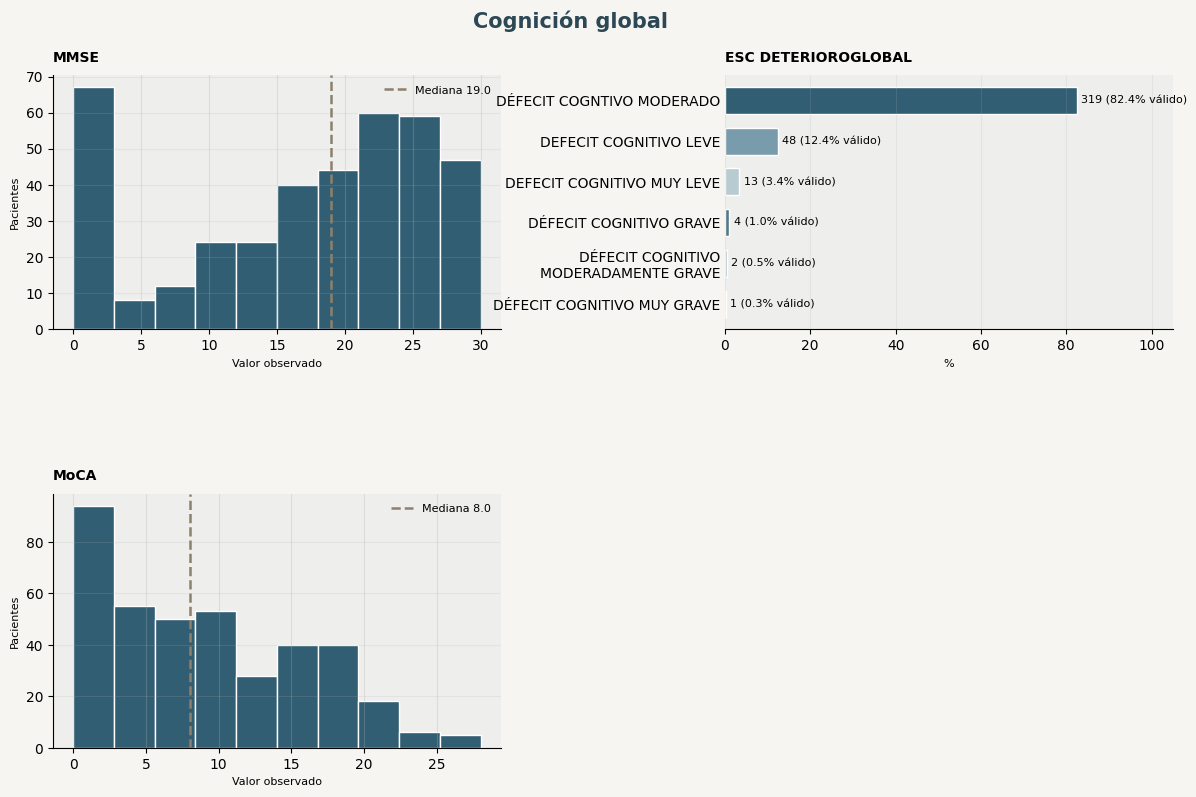

**Memoria**

**Distribuciones**

Variables integradas en la familia: **11** · graficadas: **11** · resumidas sin gráfico: **0**

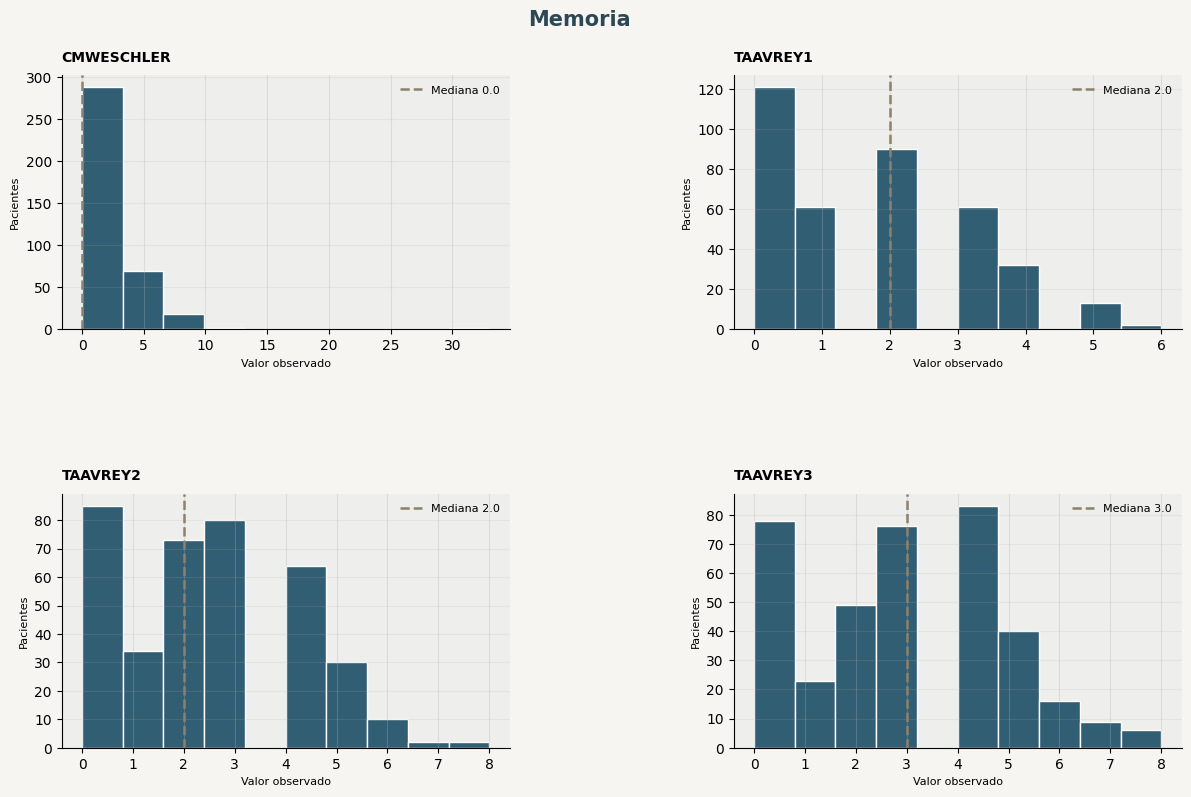

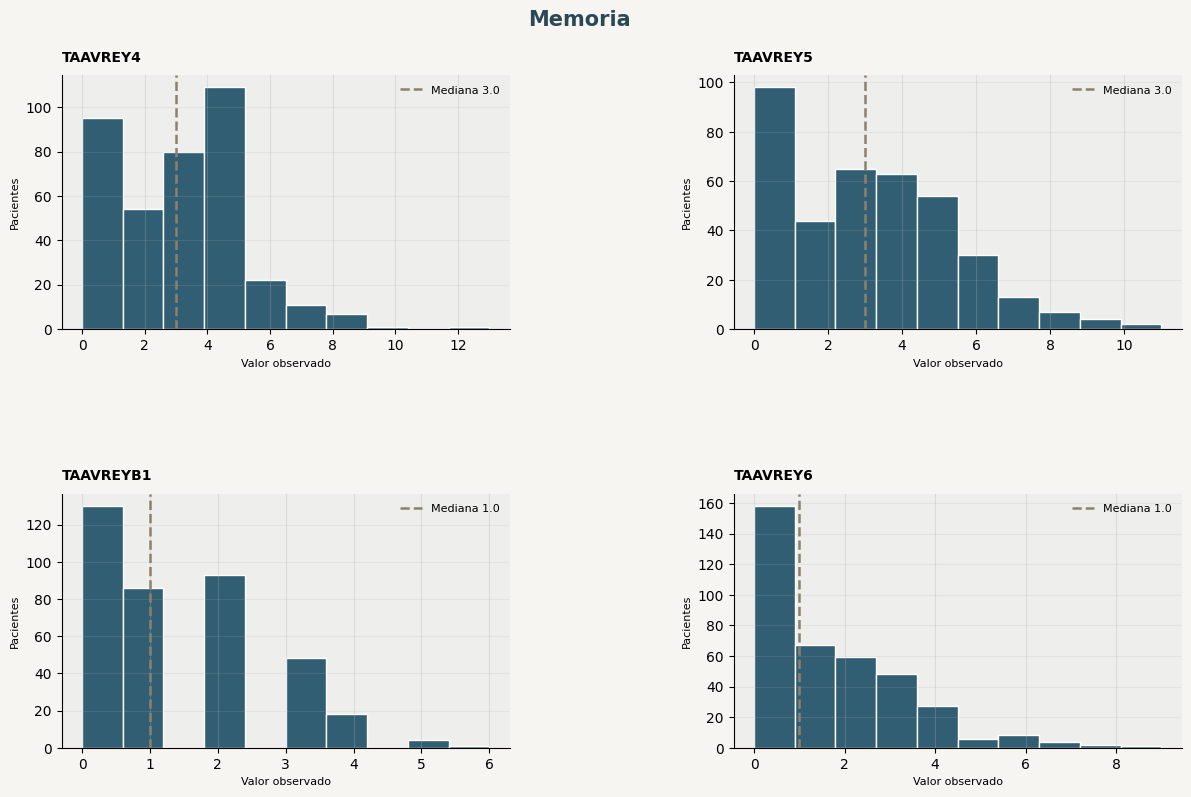

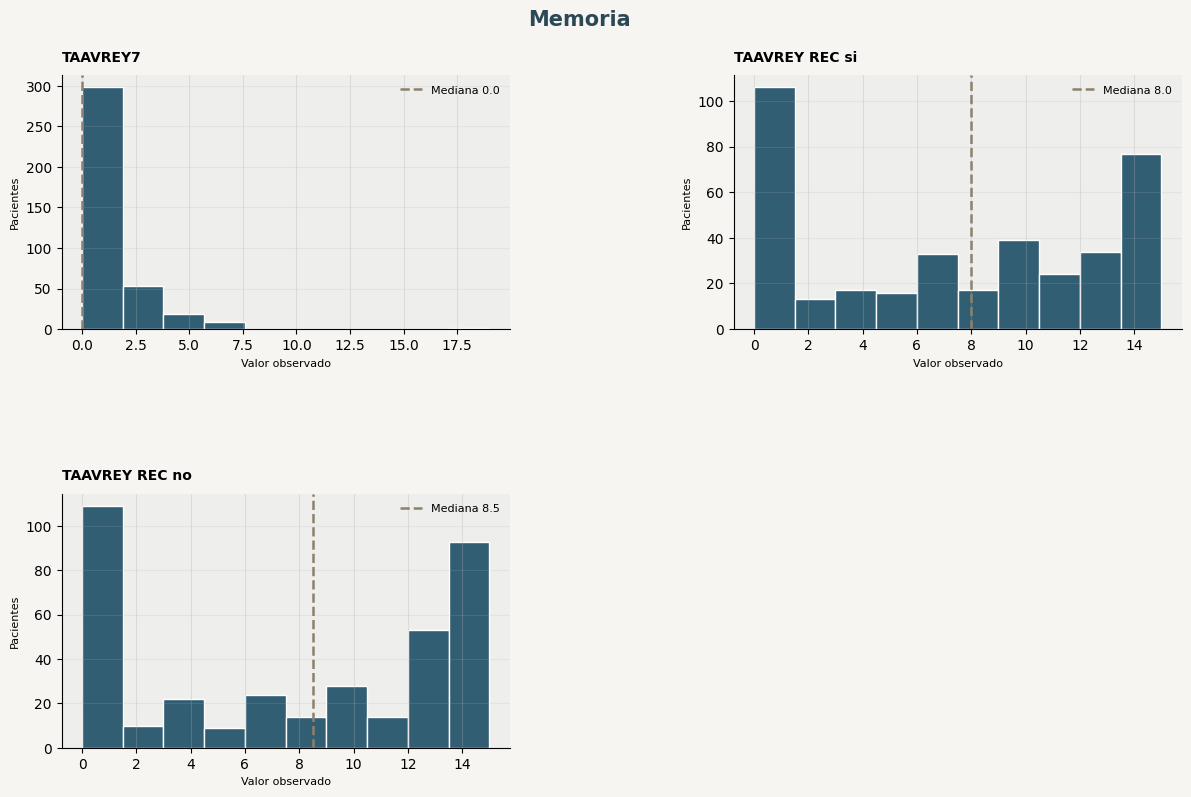

**Fluidez verbal**

**Distribuciones**

Variables integradas en la familia: **15** · graficadas: **15** · resumidas sin gráfico: **0**

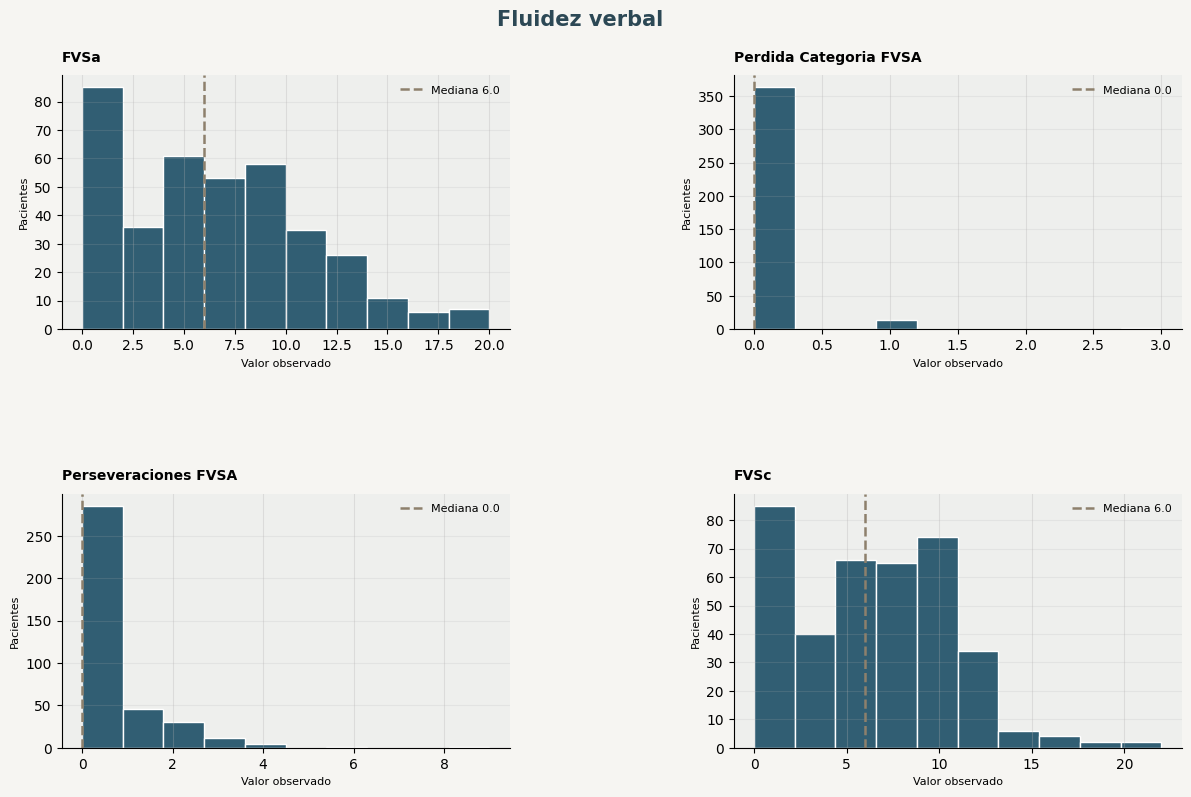

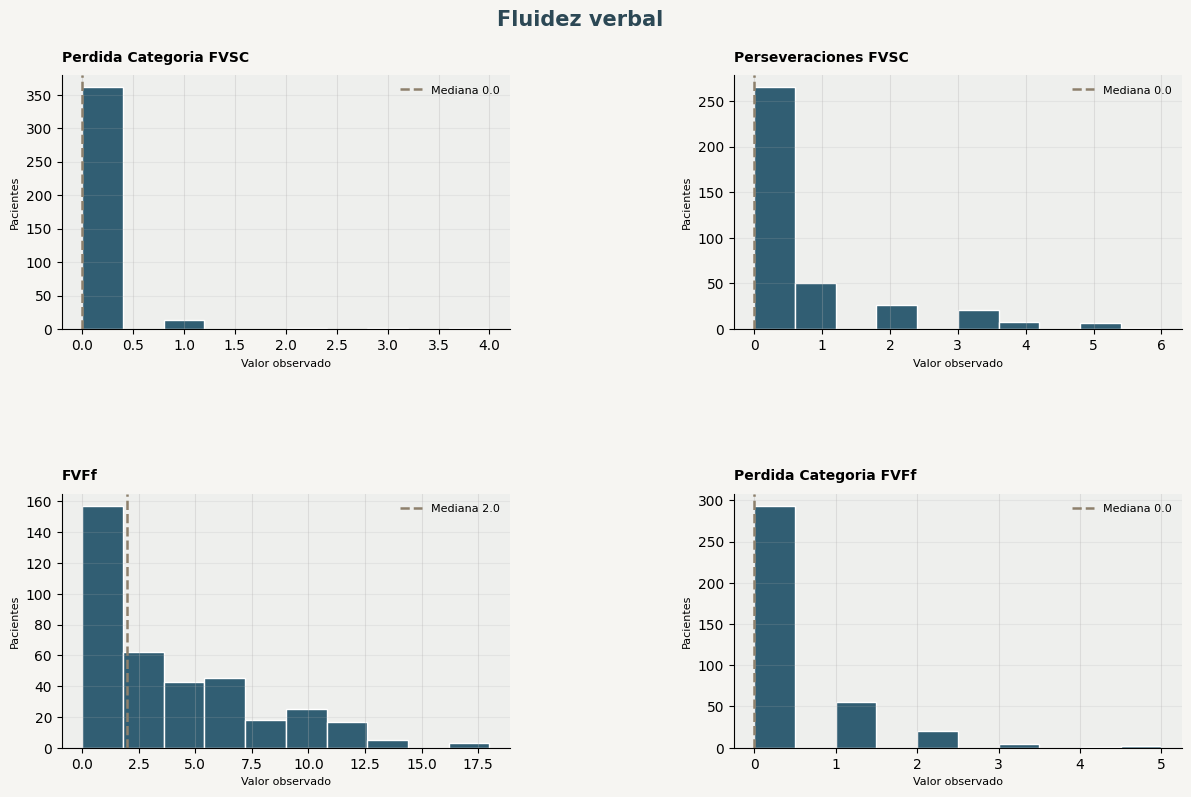

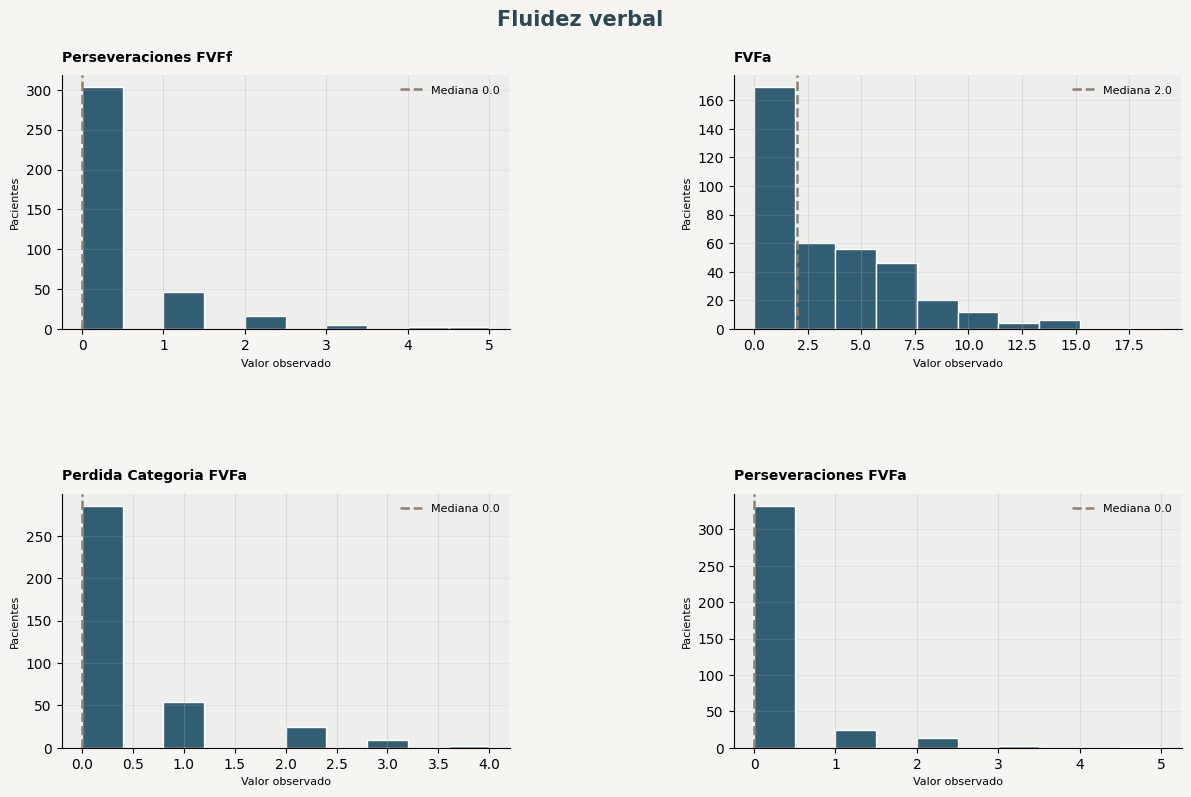

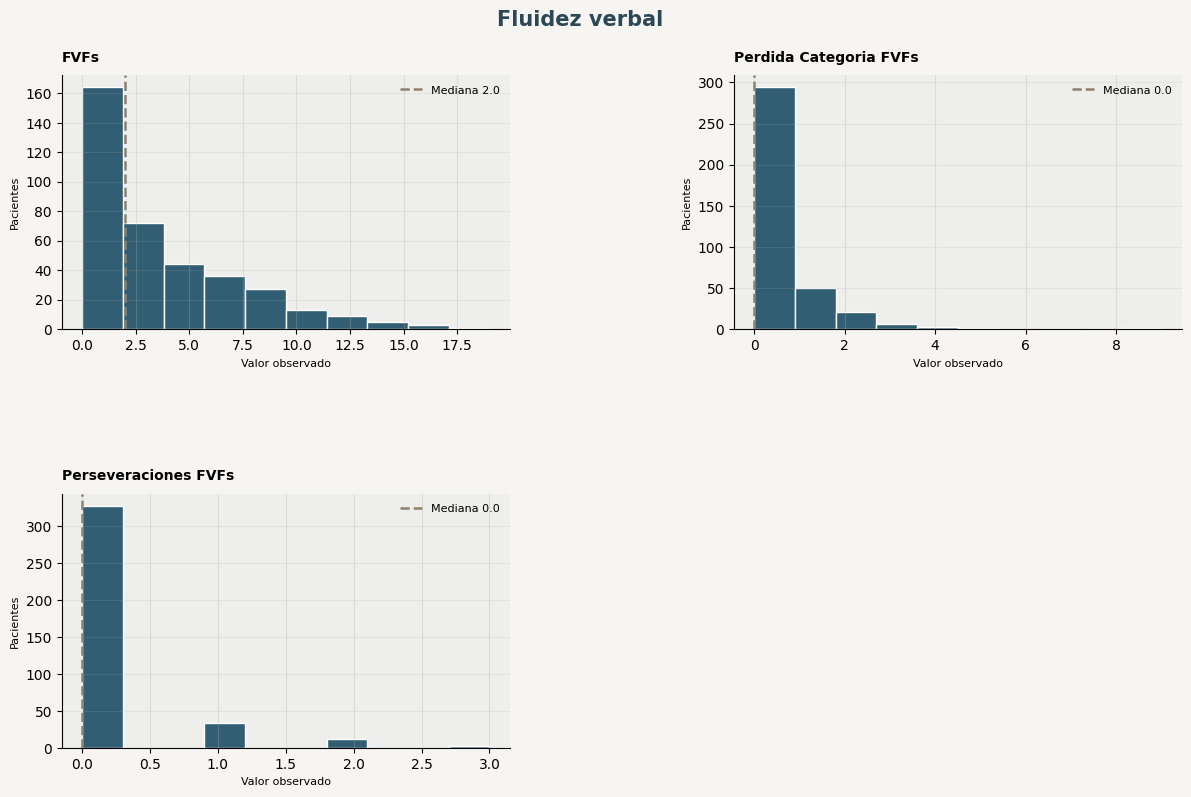

**Lenguaje**

**Distribuciones**

Variables integradas en la familia: **4** · graficadas: **4** · resumidas sin gráfico: **0**

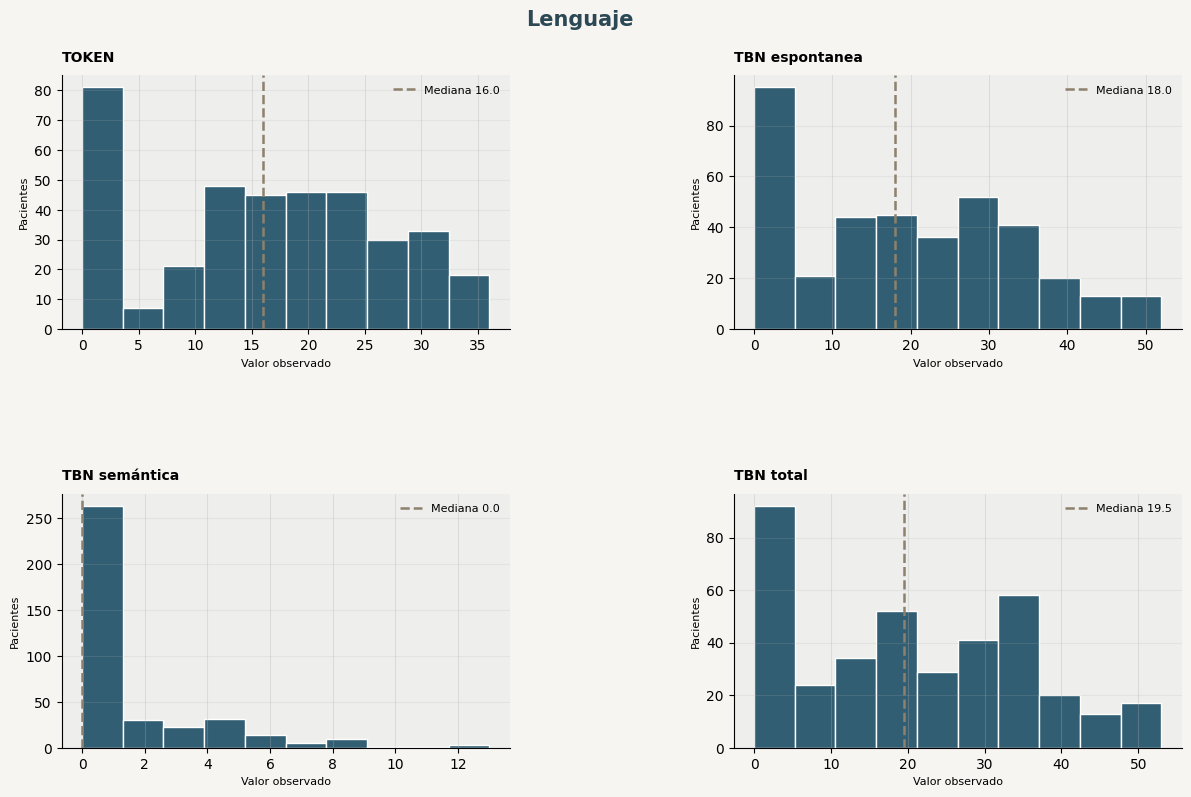

**Praxia y visuoconstrucción**

**Distribuciones**

Variables integradas en la familia: **3** · graficadas: **3** · resumidas sin gráfico: **0**

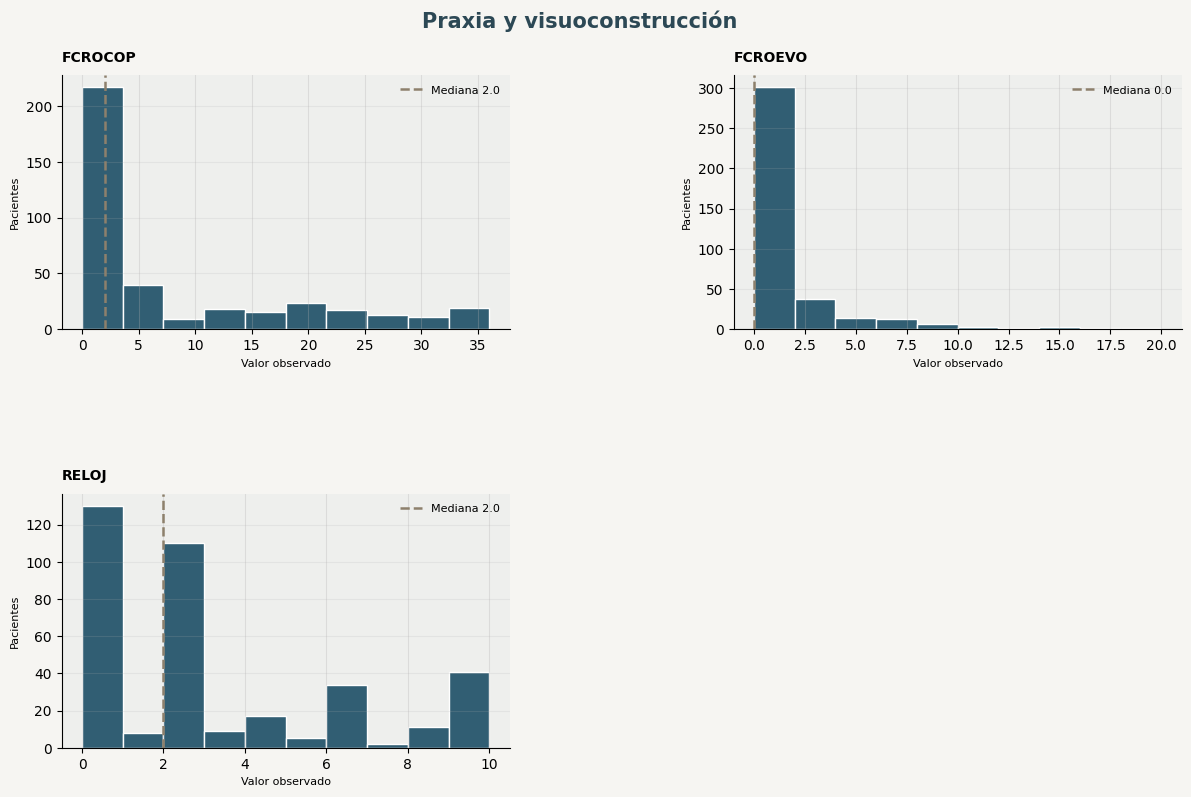

**Memoria semántica y conocimiento**

**Distribuciones**

Variables integradas en la familia: **3** · graficadas: **3** · resumidas sin gráfico: **0**

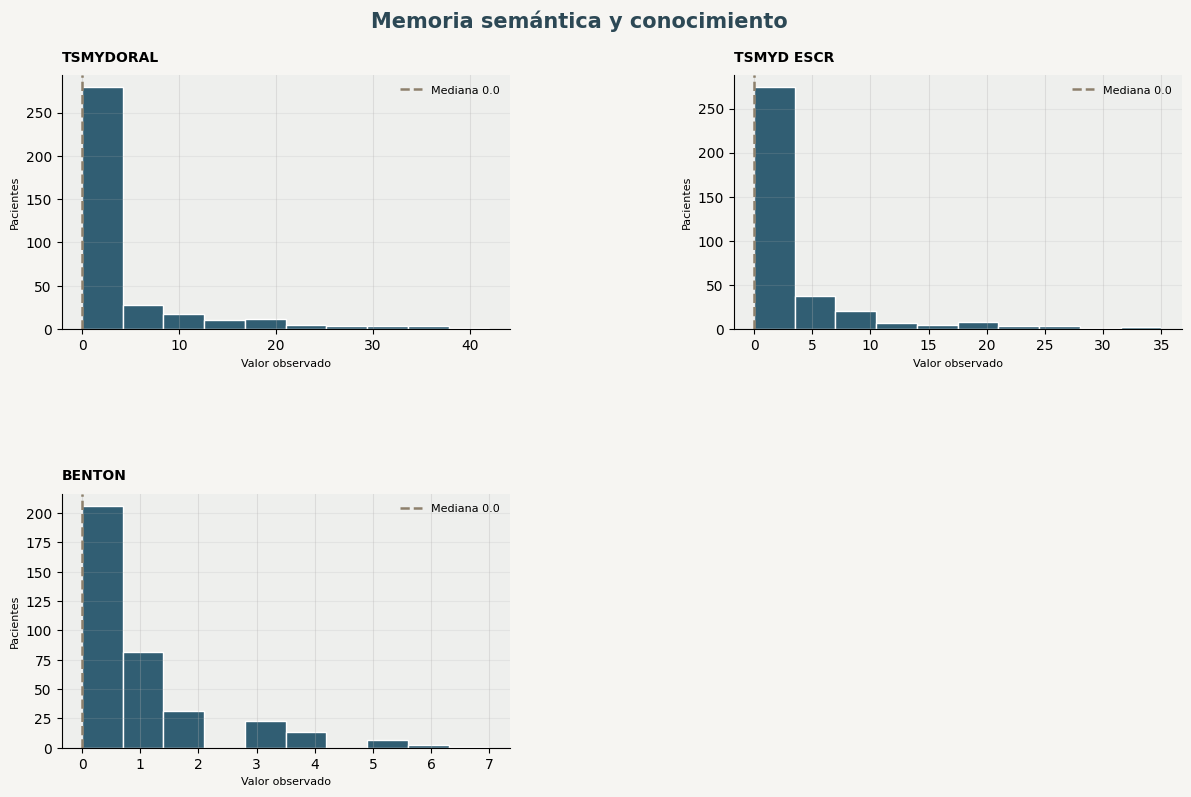

**Estado funcional, afectivo y quejas**

**Resumen de variables categóricas**

Variable,Categoría predominante,n,% válido,Faltantes
FAST,DISMINUCION EN LA CAPACIDAD ORGANIZACIONAL,193,49.7,3


**Distribuciones**

Variables integradas en la familia: **6** · graficadas: **5** · resumidas sin gráfico: **1**

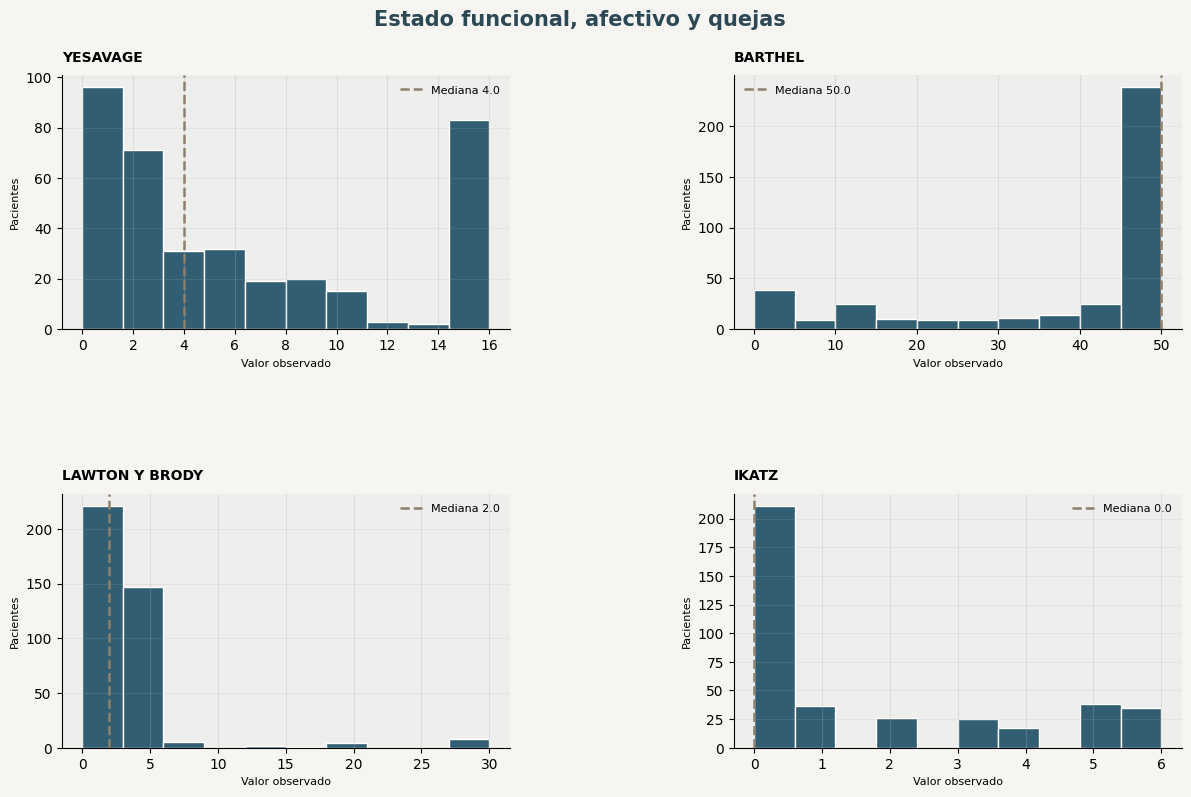

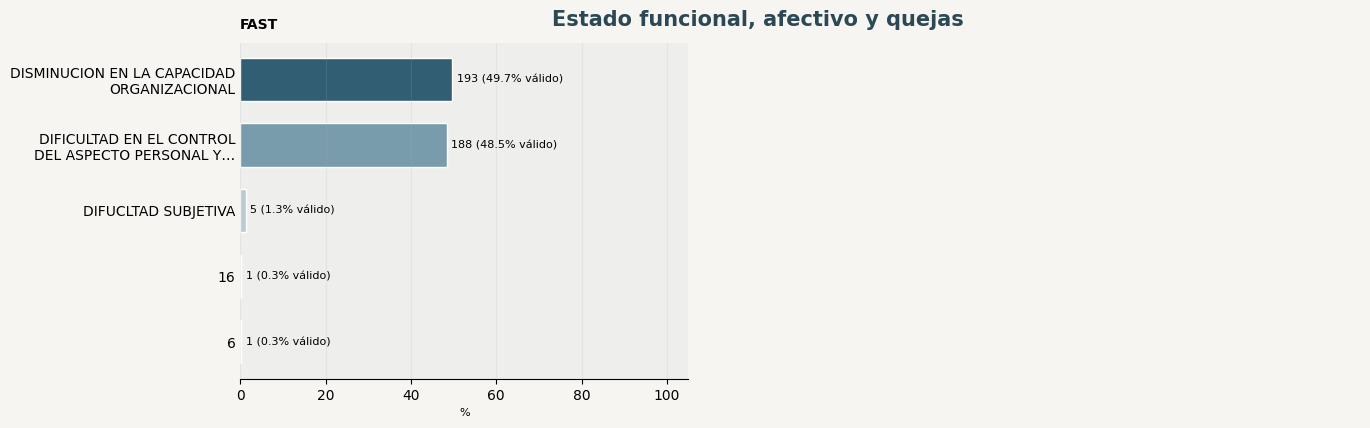

&nbsp;

**Variables no graficadas por alta cardinalidad o tipo de dato**

Variable,Tipo,n válido,Faltantes,n únicos
QUEJAS SUBJETIVAS,texto libre / alta cardinalidad,383,8,7


In [39]:

dominios_nps={
    "cognicion_global":"Cognición global",
    "memoria":"Memoria",
    "fluidez_verbal":"Fluidez verbal",
    "lenguaje":"Lenguaje",
    "praxia_visuoconstruccion":"Praxia y visuoconstrucción",
    "funciones_ejecutivas_atencion":"Funciones ejecutivas y atención",
    "memoria_semantica_conocimiento":"Memoria semántica y conocimiento",
    "funcional_afectivo_quejas":"Estado funcional, afectivo y quejas"
}

for familia,titulo in dominios_nps.items():
    if familia in inventario["familia"].values:
        display(Markdown(f"**{titulo}**"))
        ejecutar_familia(familia,titulo,
                 inventario, base_full,
                 CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)

#### **Hallazgos principales**

Las tres medidas muestran perfiles distintos de desempeño cognitivo y funcional. En MMSE, la mediana es de 19 puntos y la distribución es bastante amplia, con presencia de valores desde 0 hasta cerca de 30. Esto indica una heterogeneidad importante en el rendimiento cognitivo global de la cohorte, con un grupo considerable de pacientes en valores bajos y otro grupo concentrado en puntuaciones intermedias-altas.

En MoCA, la mediana es de 8 puntos y la distribución se concentra más hacia valores bajos, aunque también existen pacientes con puntuaciones más altas. Esto sugiere que, dentro de la cohorte, una proporción importante presenta bajo desempeño en esta medida de cognición global.

En FAST, casi toda la cohorte se concentra en las categorías 3 y 4, que representan aproximadamente el 49,7% y 48,4% de los registros válidos, respectivamente. Las demás categorías aparecen de forma muy infrecuente. Esto indica una fuerte concentración del estado funcional en dos niveles principales dentro de la muestra. Además, aparece un valor 16 con un solo registro, que conviene revisar porque se aparta claramente del patrón de codificación observado y podría corresponder a un error de digitación o a una codificación especial.

<br>

## **17. Resumen de hallazgos univariados y pendientes**

La sección caracteriza la cohorte completa sin imputar AOO, descartar extremos ni usar pruebas de hipótesis. Para el informe deben conservarse los denominadores de cada variable. Los códigos categóricos no documentados requieren confirmación de su significado y orden; las comorbilidades, medicación y medidas clínicas requieren confirmar si precedieron al inicio. El riesgo de leakage consignado en el diccionario orienta su uso futuro, pero no modifica estas descripciones.

In [40]:
n_neuro_revisadas = (
    len(tabla_seleccion_neuro) if "tabla_seleccion_neuro" in globals()
    else len(calidad_neuro) if "calidad_neuro" in globals()
    else inventario["grupo_principal"].eq("neuropsicologica").sum()
)

resumen_21 = pd.DataFrame({
    "Indicador": [
        "Pacientes",
        "AOO disponible",
        "Variables clínicas inventariadas",
        "Variables sin asignación validada",
        "Neuropsicológicas revisadas",
    ],
    "Valor": [
        len(base_full),
        int(base_full["aoo"].notna().sum()),
        int((~inventario["tipo_analitico"].isin(["identificador", "variable auxiliar del EDA"])).sum()),
        int(inventario["familia"].eq("sin_asignacion_validada").sum()),
        int(n_neuro_revisadas),
    ],
})

subtitulo("Resumen de la sección")
mostrar_tabla(resumen_21, alto=250, centrar=True, espacio=24)

pendientes_familia = inventario.loc[
    inventario["familia"].eq("sin_asignacion_validada"),
    ["etiqueta", "fuente", "tipo_analitico", "observacion"]
].reset_index(drop=True)

if pendientes_familia.empty:
    display(Markdown("**Asignación por familia:** todas las variables integradas quedaron asignadas."))
else:
    subtitulo("Variables pendientes de asignación por familia")
    mostrar_tabla(
        pendientes_familia,
        alto=300,
        renombrar={
            "etiqueta": "Variable",
            "fuente": "Fuente",
            "tipo_analitico": "Tipo analítico",
            "observacion": "Observación",
        },
        ajustar_texto=True,
        anchos={"Variable": 260, "Observación": 300},
        espacio=24,
    )

assert len(base_full) == 391
assert base_full["id"].is_unique
assert not any(
    c in inventario["columna"].values
    for c in ["match_neuro", "match_moca", "aoo_original", "aoo_actualizada"]
)

**Resumen de la sección**

Indicador,Valor
Pacientes,391
AOO disponible,334
Variables clínicas inventariadas,144
Variables sin asignación validada,0
Neuropsicológicas revisadas,54


**Asignación por familia:** todas las variables integradas quedaron asignadas.

<br>

## **Exportación para el análisis bivariado**

El bivariado usa `base_full` e `inventario`.

In [41]:
SALIDAS.mkdir(exist_ok=True)

base_full.to_pickle(SALIDAS / "base_full_univariado.pkl")
inventario.to_pickle(SALIDAS / "inventario.pkl")

print("base_full:", base_full.shape, "| inventario:", inventario.shape)

base_full: (391, 161) | inventario: (146, 25)
